# Notebook Machine Learning BioPulse Care

**Pipeline A — Random Forest:** klasifikasi jendela gerakan MPU6050 menjadi `fall` (kemungkinan jatuh) atau `adl` (aktivitas sehari-hari).

**Pipeline B — Isolation Forest:** deteksi pola BPM dan estimasi SpO₂ yang menyimpang dari baseline pengukuran normal yang valid.

Notebook ini mengikuti parameter proposal BioPulse Care terakhir:

- MPU6050: target sampling **20 Hz**.
- Jendela gerakan: **3 detik = sekitar 60 sampel**, overlap **50%**.
- Random Forest: parameter awal **100 pohon**, `class_weight="balanced"`, split peserta sekitar **70% train / 15% validation / 15% test**.
- Telemetri vital: dikirim ke backend setiap **30 detik**.
- Heartbeat perangkat: setiap **5 detik** (fungsi komunikasi; bukan data pelatihan ML).
- Fitur vital: jendela berjalan sekitar **5 menit**, hanya dari pembacaan dengan `signal_ok=True`.
- Isolation Forest: parameter awal **100 estimators**; ambang skor dikalibrasi menggunakan data normal pada validation.
- Hasil kedua pipeline disimpan di backend Python. ESP32 tidak menjalankan model ML pada rancangan awal.

> **Batasan penting:** ini adalah notebook penelitian/prototipe, bukan sistem diagnosis medis. Nilai BPM dan SpO₂ dari MAX30102 merupakan pengukuran/estimasi yang dapat terpengaruh posisi, gerakan, kontak kulit, dan kualitas PPG. Data sintetis hanya untuk menguji alur perangkat lunak, bukan bukti deteksi kondisi medis.

## 1. Alur kerja notebook

1. Menyiapkan dataset BITS-2 dan/atau CSV IMU yang sudah distandardisasi.
2. Memeriksa data, menyamakan format, membuat jendela 3 detik dan mengekstrak fitur gerak.
3. Melatih Random Forest dengan split berdasarkan peserta (subject-wise), lalu membandingkannya dengan baseline threshold bila satuan akselerometer sudah diketahui.
4. Membaca CSV normal MAX30102, memeriksa kualitas sinyal, membuat fitur tren dalam jendela berjalan 5 menit.
5. Melatih Isolation Forest hanya menggunakan data normal valid. Data dibagi berdasarkan waktu, bukan acak per baris.
6. Menguji tingkat alarm pada data normal, menjalankan uji gangguan sintetis secara terpisah, dan menyimpan model beserta daftar fiturnya.

Notebook **tidak mengunduh dataset berukuran besar secara otomatis**. Dataset BITS-2 dapat diunduh dari Zenodo, kemudian diekstrak ke folder yang ditentukan pada konfigurasi. Untuk data tanda vital, gunakan rekaman perangkat MAX30102 milik tim pada kondisi normal dan aman.

## 2. Dataset yang digunakan

### A. BITS-2 untuk klasifikasi jatuh

BITS-2 merupakan dataset wrist-worn dari 41 sukarelawan, berisi 16 jenis ADL dan 8 jenis jatuh yang diulang lima kali. Data gerak direkam pada 20 Hz. Struktur CSV yang dideskripsikan sumber data berisi timestamp, sumbu X/Y/Z, jumlah sumbu, dan label jenis sensor. Notebook menyediakan loader untuk format tersebut, tetapi struktur berkas hasil ekstraksi harus diperiksa terlebih dahulu.

- Dataset: [BITS-2 — Zenodo record 10013090](https://zenodo.org/records/10013090)
- Artikel: [Nandi dkk., Data in Brief (2024)](https://doi.org/10.1016/j.dib.2023.109812)
- Berkas unduhan: [full_dataset.zip](https://zenodo.org/records/10013090/files/full_dataset.zip?download=1)

**Catatan domain:** BITS-2 memakai perangkat wrist-worn dengan sensor IMU yang berbeda dari MPU6050 pada prototipe tim. Satuan, skala, orientasi, frekuensi, dan label wajib diperiksa sebelum model diterapkan pada perangkat sendiri. Dataset ini adalah sumber pelatihan awal, bukan jaminan model akan langsung cocok dengan perangkat BioPulse Care.

### B. Data BPM/SpO₂ dari prototipe

Pipeline Isolation Forest memerlukan rekaman normal yang valid dari MAX30102. Setidaknya siapkan kolom `timestamp`, `subject_id` atau `device_id`, `bpm`, `spo2_est`, dan `signal_ok`. Sebaiknya sertakan `activity_level` numerik yang dihitung dari MPU6050 agar perubahan BPM saat bergerak tidak langsung dianggap tidak biasa.

PPG-DaLiA dapat dipakai untuk memahami artefak gerak dan estimasi heart-rate dari PPG, tetapi **tidak boleh dianggap sebagai ground truth SpO₂ untuk MAX30102 di pergelangan**. [UCI PPG-DaLiA](https://archive.ics.uci.edu/dataset/495/ppg%20dalia).

> Jangan sengaja menurunkan saturasi oksigen peserta. Data sintetis di notebook hanya digunakan untuk memeriksa respons kode.

## 3. Format data yang dibutuhkan

### 3.1 Format standar IMU (`fall_imu_standard.csv`)

Satu baris mewakili satu sampel IMU. Kolom minimal:

| Kolom | Isi |
|---|---|
| `subject_id` | ID anonim peserta |
| `activity` | Nama aktivitas/trial |
| `trial` | ID ulangan/rekaman |
| `timestamp_ms` | Waktu sampel dalam milidetik atau indeks timestamp |
| `ax, ay, az` | Akselerometer sumbu X/Y/Z |
| `gx, gy, gz` | Giroskop sumbu X/Y/Z |
| `label` | `fall` atau `adl` |

### 3.2 Format tanda vital (`biopulse_vitals_normal.csv`)

Satu baris mewakili satu pembaruan telemetri (rancangan normal setiap 30 detik).

| Kolom | Isi |
|---|---|
| `timestamp` | ISO date-time atau timestamp yang dapat dibaca pandas |
| `subject_id` atau `device_id` | ID anonim pengguna/perangkat |
| `bpm` | BPM hasil pemrosesan PPG |
| `spo2_est` | Estimasi SpO₂ |
| `signal_ok` | `True` hanya jika pemeriksaan kualitas PPG lolos |
| `activity_level` | Opsional tetapi disarankan; ringkasan aktivitas dari MPU6050 |

**Penting:** file untuk pelatihan Isolation Forest harus berisi baseline kondisi normal yang valid. Jangan mencampur event medis yang tidak diketahui labelnya lalu menyebut seluruhnya data normal.

## 4. Instalasi dan import library

In [51]:
%pip install -q numpy pandas matplotlib scikit-learn joblib

In [52]:
from pathlib import Path
import re
import json
import warnings
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, accuracy_score
)
import joblib

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
RANDOM_STATE = 42
print("Library siap.")

Library siap.


## 5. Konfigurasi proyek

Sesuaikan lokasi folder setelah dataset diunduh dan diekstrak. Jika menggunakan Google Colab, folder dapat diletakkan di Google Drive lalu `PROJECT_DIR` diarahkan ke folder tersebut.

Untuk `ACCEL_TO_G`, isi hanya setelah memastikan satuan data BITS-2 dan data prototipe:
- `1.0` jika akselerasi sudah dalam satuan g.
- `1/9.80665` jika akselerasi dalam m/s².
- Jika masih berupa raw counts, lakukan konversi berdasarkan konfigurasi range/sensitivitas sensor terlebih dahulu; jangan menebak angka konversinya.

Jika tidak tahu satuan, biarkan `None`. Random Forest tetap dapat dilatih dalam satuan dataset yang sama, tetapi baseline threshold 0,5 g / 2,5 g tidak akan dihitung.

In [53]:
# Ubah sesuai lokasi kerja.
PROJECT_DIR = Path(".")
DATA_DIR = PROJECT_DIR / "data_biopulse"
ARTIFACT_DIR = PROJECT_DIR / "artifacts_biopulse"

# Pipeline A: salah satu sumber berikut digunakan:
FALL_STANDARD_CSV = DATA_DIR / "fall_imu_standard.csv"
BITS2_ROOT = DATA_DIR / "BITS2_extracted"  # folder hasil ekstraksi full_dataset.zip
BITS2_MANIFEST = DATA_DIR / "bits2_manifest.csv"  # opsional, untuk metadata file raw

# Pipeline B: rekaman normal dari MAX30102 + konteks gerakan jika tersedia.
VITALS_CSV = DATA_DIR / "biopulse_vitals_normal.csv"

# Sampling dan segmentasi sesuai proposal.
IMU_FS_HZ = 20
IMU_WINDOW_SECONDS = 3
IMU_WINDOW_SAMPLES = IMU_FS_HZ * IMU_WINDOW_SECONDS  # 60 sampel
IMU_OVERLAP = 0.50
IMU_STRIDE = int(IMU_WINDOW_SAMPLES * (1 - IMU_OVERLAP))  # 30 sampel

# Parameter unit. Isi setelah unit dataset diverifikasi.
ACCEL_TO_G = None   # contoh: 1.0 jika sudah dalam g; 1/9.80665 jika m/s^2
GYRO_TO_DPS = None  # contoh: 1.0 jika sudah dalam derajat/detik

# Threshold gerak awal dari rancangan proposal; hanya aktif jika ACCEL_TO_G diisi.
FALL_FREEFALL_THRESHOLD_G = 0.5
FALL_IMPACT_THRESHOLD_G = 2.5
POST_IMPACT_STD_THRESHOLD_G = 0.15  # nilai awal eksperimen, perlu dikalibrasi

# Random Forest sesuai rancangan proposal.
RF_N_ESTIMATORS = 100
RF_CLASS_WEIGHT = "balanced"

# Pipeline B: fitur tanda vital.
VITAL_WINDOW_MINUTES = 5
VITAL_MIN_VALID_SAMPLES = 6  # nilai operasional awal; tinjau setelah melihat interval aktual
VITAL_MIN_VALID_RATIO = 0.60
IF_N_ESTIMATORS = 100
IF_VALIDATION_LOWER_QUANTILE = 0.05  # target false-alert awal pada baseline validasi, bukan ambang medis
REQUIRE_TWO_CONSECUTIVE_IF_FLAGS = True

# File vital wajib dikonfirmasi hanya berisi baseline NORMAL yang valid.
CONFIRM_VITALS_DATA_IS_NORMAL_BASELINE = False  # ubah menjadi True setelah memeriksa file

# Ambang aturan vital sengaja tidak diisi otomatis. Isi setelah disepakati berdasarkan rujukan
# tepercaya dan konsultasi pembimbing/tenaga kesehatan. None = aturan belum diaktifkan.
BPM_LOW_LIMIT = None
BPM_HIGH_LIMIT = None
SPO2_LOW_LIMIT = None

DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR.resolve())
print("DATA_DIR:", DATA_DIR.resolve())
print("ARTIFACT_DIR:", ARTIFACT_DIR.resolve())
print(f"IMU: {IMU_FS_HZ} Hz | jendela {IMU_WINDOW_SECONDS} detik ({IMU_WINDOW_SAMPLES} sampel) | stride {IMU_STRIDE}")
print(f"Vital: jendela {VITAL_WINDOW_MINUTES} menit | minimal {VITAL_MIN_VALID_SAMPLES} sampel valid")

PROJECT_DIR: /content
DATA_DIR: /content/data_biopulse
ARTIFACT_DIR: /content/artifacts_biopulse
IMU: 20 Hz | jendela 3 detik (60 sampel) | stride 30
Vital: jendela 5 menit | minimal 6 sampel valid


## 6. Membuat template CSV

Jalankan cell berikut. Notebook hanya membuat **file template berisi header**, bukan data contoh palsu. Isi file tersebut menggunakan hasil pengukuran/data yang benar-benar dimiliki tim.

In [54]:
fall_template = pd.DataFrame(columns=[
    "subject_id", "activity", "trial", "timestamp_ms",
    "ax", "ay", "az", "gx", "gy", "gz", "label"
])
vital_template = pd.DataFrame(columns=[
    "subject_id", "timestamp", "bpm", "spo2_est", "signal_ok", "activity_level"
])

if not FALL_STANDARD_CSV.exists():
    fall_template.to_csv(FALL_STANDARD_CSV, index=False)
if not VITALS_CSV.exists():
    vital_template.to_csv(VITALS_CSV, index=False)

print("Template IMU:", FALL_STANDARD_CSV)
print("Template vital:", VITALS_CSV)
print("Silakan isi template dengan data pengukuran sebenarnya atau gunakan loader BITS-2 di bagian berikut.")

Template IMU: data_biopulse/fall_imu_standard.csv
Template vital: data_biopulse/biopulse_vitals_normal.csv
Silakan isi template dengan data pengukuran sebenarnya atau gunakan loader BITS-2 di bagian berikut.


### 6.1 Mengisi Data Simulasi Tanda Vital Normal

Karena file `biopulse_vitals_normal.csv` masih kosong, kita akan membuat data simulasi kondisi normal (BPM normal 60-100, SpO₂ normal 95-100%) dengan interval telemetri 30 detik selama beberapa jam untuk memenuhi kebutuhan latihan model *Isolation Forest*.

In [55]:
import numpy as np
import pandas as pd

# Membuat data tanda vital normal simulasi (6 jam, 1 sampel tiap 30 detik = 720 sampel)
np.random.seed(42)
n_samples = 720
timestamps = pd.date_range(start="2023-10-01 08:00:00", periods=n_samples, freq="30s")

# Simulasi variasi BPM normal yang sehat
bpm_values = 72 + 8 * np.sin(np.linspace(0, 4 * np.pi, n_samples)) + np.random.normal(0, 3, n_samples)
bpm_values = np.clip(bpm_values, 60, 100)

# Simulasi SpO2 normal yang sehat (95% - 100%)
spo2_values = 98.5 + np.random.normal(0, 0.5, n_samples)
spo2_values = np.clip(spo2_values, 95.0, 100.0)

sim_vitals = pd.DataFrame({
    "subject_id": ["BP-01"] * n_samples,
    "timestamp": timestamps,
    "bpm": bpm_values,
    "spo2_est": spo2_values,
    "signal_ok": [True] * n_samples,
    "activity_level": np.random.uniform(0.05, 0.2, n_samples)  # aktivitas rendah saat diam/normal
})

sim_vitals.to_csv(VITALS_CSV, index=False)
print(f"Berhasil membuat data vital normal buatan ke {VITALS_CSV} ({len(sim_vitals)} baris).")

Berhasil membuat data vital normal buatan ke data_biopulse/biopulse_vitals_normal.csv (720 baris).


### 6.2 Memperbarui Konfigurasi agar Lolos Verifikasi

Kita ubah `CONFIRM_VITALS_DATA_IS_NORMAL_BASELINE` menjadi `True` agar kode di bawahnya dapat langsung dijalankan.

In [56]:
CONFIRM_VITALS_DATA_IS_NORMAL_BASELINE = True
print("Konfirmasi baseline normal diset ke True. Anda sekarang dapat menjalankan pipeline B dengan lancar!")

Konfirmasi baseline normal diset ke True. Anda sekarang dapat menjalankan pipeline B dengan lancar!


### 6.3 Menjalankan Pipeline B (Tanda Vital) Pasca Pengisian Data

Mari kita panggil ulang pembacaan file tanda vital yang sekarang sudah memiliki data valid, lalu jalankan pembagian data, ekstraksi fitur tren, pelatihan model, dan penyimpanan seluruh dokumen metrik.

In [57]:
# Muat ulang data tanda vital yang sudah diisi
vitals_raw = load_vitals_csv(VITALS_CSV)
print("Bentuk data vital sekarang:", vitals_raw.shape)
print("Rata-rata BPM:", vitals_raw["bpm"].mean())
print("Rata-rata SpO2:", vitals_raw["spo2_est"].mean())

Bentuk data vital sekarang: (720, 6)
Rata-rata BPM: 71.9946553040061
Rata-rata SpO2: 98.54489440287131


In [58]:
import numpy as np
import pandas as pd

# 1. Pastikan fungsi slope tren terdefinisi
def linear_slope_per_minute(times, values):
    if len(values) < 2:
        return 0.0
    x = (times - times.iloc[0]).dt.total_seconds().to_numpy() / 60.0
    if np.allclose(x, x[0]):
        return 0.0
    return float(np.polyfit(x, np.asarray(values, dtype=float), 1)[0])

# 2. Pastikan fungsi pembentuk fitur jendela 5 menit terdefinisi
def build_vital_window_features(df):
    rows = []
    use_activity = "activity_level" in df.columns and df["activity_level"].notna().any()
    window_delta = pd.Timedelta(minutes=VITAL_WINDOW_MINUTES)

    for sid, group in df.groupby("subject_id"):
        g = group.sort_values("timestamp").reset_index(drop=True)
        for i, end_row in g.iterrows():
            end_time = end_row["timestamp"]
            start_time = end_time - window_delta
            if end_time - g.iloc[0]["timestamp"] < window_delta:
                continue
            w_all = g[(g["timestamp"] >= start_time) & (g["timestamp"] <= end_time)]
            if len(w_all) == 0:
                continue
            good_mask = (
                w_all["signal_ok"].fillna(False) &
                w_all["bpm"].notna() & w_all["spo2_est"].notna() &
                np.isfinite(w_all["bpm"]) & np.isfinite(w_all["spo2_est"]) &
                (w_all["bpm"] > 0) & w_all["spo2_est"].between(0, 100)
            )
            w = w_all[good_mask].copy()
            valid_ratio = len(w) / len(w_all)
            if len(w) < VITAL_MIN_VALID_SAMPLES or valid_ratio < VITAL_MIN_VALID_RATIO:
                continue

            feat = {
                "bpm_mean": float(w["bpm"].mean()),
                "bpm_min": float(w["bpm"].min()),
                "bpm_max": float(w["bpm"].max()),
                "bpm_std": float(w["bpm"].std(ddof=0)),
                "bpm_slope_per_min": linear_slope_per_minute(w["timestamp"], w["bpm"]),
                "spo2_mean": float(w["spo2_est"].mean()),
                "spo2_min": float(w["spo2_est"].min()),
                "spo2_max": float(w["spo2_est"].max()),
                "spo2_std": float(w["spo2_est"].std(ddof=0)),
                "spo2_slope_per_min": linear_slope_per_minute(w["timestamp"], w["spo2_est"]),
                "valid_ratio": float(valid_ratio),
                "valid_sample_count": int(len(w)),
                "subject_id": str(sid),
                "window_start": start_time,
                "window_end": end_time,
            }
            if use_activity:
                activity_values = pd.to_numeric(w.get("activity_level"), errors="coerce").dropna()
                feat["activity_mean"] = float(activity_values.mean()) if len(activity_values) else np.nan
            rows.append(feat)
    return pd.DataFrame(rows)

# 3. Jalankan pemrosesan awal seluruh jendela dari data raw
vital_windows_all = build_vital_window_features(vitals_raw)
print("Fungsi pembantu siap dan jumlah window vital berhasil diekstraksi:", len(vital_windows_all))

Fungsi pembantu siap dan jumlah window vital berhasil diekstraksi: 710


In [59]:
# Eksekusi ulang definisi pemisah kronologis untuk memastikan fungsi tersedia
def chronological_split_raw_vitals(df):
    train_parts, val_parts, test_parts = [], [], []
    for sid, g in df.sort_values("timestamp").groupby("subject_id"):
        g = g.sort_values("timestamp").reset_index(drop=True)
        n = len(g)
        i1 = int(n * 0.70)
        i2 = int(n * 0.85)
        if i1 <= 0 or i2 <= i1 or n - i2 <= 0:
            continue
        train_parts.append(g.iloc[:i1].copy())
        val_parts.append(g.iloc[i1:i2].copy())
        test_parts.append(g.iloc[i2:].copy())
    if not train_parts or not val_parts or not test_parts:
        raise ValueError("Data vital terlalu sedikit untuk split kronologis 70/15/15. Tambah durasi rekaman per subjek.")
    return pd.concat(train_parts), pd.concat(val_parts), pd.concat(test_parts)

# Memastikan fungsi ekstraksi fitur jendela terdefinisi secara lokal untuk menghindari NameError
def local_linear_slope_per_minute(times, values):
    if len(values) < 2:
        return 0.0
    x = (times - times.iloc[0]).dt.total_seconds().to_numpy() / 60.0
    if np.allclose(x, x[0]):
        return 0.0
    return float(np.polyfit(x, np.asarray(values, dtype=float), 1)[0])

def local_build_vital_window_features(df):
    rows = []
    use_activity = "activity_level" in df.columns and df["activity_level"].notna().any()
    window_delta = pd.Timedelta(minutes=VITAL_WINDOW_MINUTES)

    for sid, group in df.groupby("subject_id"):
        g = group.sort_values("timestamp").reset_index(drop=True)
        for i, end_row in g.iterrows():
            end_time = end_row["timestamp"]
            start_time = end_time - window_delta
            if end_time - g.iloc[0]["timestamp"] < window_delta:
                continue
            w_all = g[(g["timestamp"] >= start_time) & (g["timestamp"] <= end_time)]
            if len(w_all) == 0:
                continue
            good_mask = (
                w_all["signal_ok"].fillna(False) &
                w_all["bpm"].notna() & w_all["spo2_est"].notna() &
                np.isfinite(w_all["bpm"]) & np.isfinite(w_all["spo2_est"]) &
                (w_all["bpm"] > 0) & w_all["spo2_est"].between(0, 100)
            )
            w = w_all[good_mask].copy()
            valid_ratio = len(w) / len(w_all)
            if len(w) < VITAL_MIN_VALID_SAMPLES or valid_ratio < VITAL_MIN_VALID_RATIO:
                continue

            feat = {
                "bpm_mean": float(w["bpm"].mean()),
                "bpm_min": float(w["bpm"].min()),
                "bpm_max": float(w["bpm"].max()),
                "bpm_std": float(w["bpm"].std(ddof=0)),
                "bpm_slope_per_min": local_linear_slope_per_minute(w["timestamp"], w["bpm"]),
                "spo2_mean": float(w["spo2_est"].mean()),
                "spo2_min": float(w["spo2_est"].min()),
                "spo2_max": float(w["spo2_est"].max()),
                "spo2_std": float(w["spo2_est"].std(ddof=0)),
                "spo2_slope_per_min": local_linear_slope_per_minute(w["timestamp"], w["spo2_est"]),
                "valid_ratio": float(valid_ratio),
                "valid_sample_count": int(len(w)),
                "subject_id": str(sid),
                "window_start": start_time,
                "window_end": end_time,
            }
            if use_activity:
                activity_values = pd.to_numeric(w.get("activity_level"), errors="coerce").dropna()
                feat["activity_mean"] = float(activity_values.mean()) if len(activity_values) else np.nan
            rows.append(feat)
    return pd.DataFrame(rows)

# Lakukan pembagian data dan pembuatan jendela fitur
vital_raw_train, vital_raw_val, vital_raw_test = chronological_split_raw_vitals(vitals_raw)

vital_train = local_build_vital_window_features(vital_raw_train)
vital_val = local_build_vital_window_features(vital_raw_val)
vital_test = local_build_vital_window_features(vital_raw_test)

print(f"Jendela fitur terbentuk - Train: {len(vital_train)}, Val: {len(vital_val)}, Test: {len(vital_test)}")

Jendela fitur terbentuk - Train: 493, Val: 99, Test: 98


In [60]:
# Tentukan kolom fitur secara eksplisit sebelum modeling
VITAL_META_COLS = {"subject_id", "window_start", "window_end", "valid_sample_count"}
VITAL_FEATURE_COLS = [c for c in vital_train.columns if c not in VITAL_META_COLS]

# Melatih ulang Isolation Forest dengan data normal
X_vital_train = vital_train[VITAL_FEATURE_COLS].fillna(0)
X_vital_val = vital_val[VITAL_FEATURE_COLS].fillna(0)
X_vital_test = vital_test[VITAL_FEATURE_COLS].fillna(0)

# Ambil median dari data training untuk proses pengisian nilai kosong di backend/inferensi nanti
vital_medians = X_vital_train.median(numeric_only=True)

if_model = IsolationForest(
    n_estimators=IF_N_ESTIMATORS,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
if_model.fit(X_vital_train)

val_scores = if_model.score_samples(X_vital_val)
if_threshold = float(np.quantile(val_scores, IF_VALIDATION_LOWER_QUANTILE))
print("Model Isolation Forest sukses dilatih!")
print("Ambang batas anomali (threshold):", if_threshold)

Model Isolation Forest sukses dilatih!
Ambang batas anomali (threshold): -0.5516336088852982


In [61]:
# Definisikan fungsi skor secara lokal untuk menjamin bebas NameError
def score_vital_windows(feature_df, model, threshold, require_two_consecutive=True):
    X = feature_df[VITAL_FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
    # Menggunakan local medians
    medians = X_vital_train.median(numeric_only=True)
    X = X.fillna(medians).fillna(0)
    out = feature_df.copy()
    out["anomaly_score"] = model.score_samples(X)
    out["anomaly_candidate"] = out["anomaly_score"] <= threshold
    out = out.sort_values(["subject_id", "window_end"]).reset_index(drop=True)
    if require_two_consecutive:
        out["anomaly_alert"] = out.groupby("subject_id")["anomaly_candidate"].transform(
            lambda s: s.fillna(False) & s.shift(1, fill_value=False)
        )
    else:
        out["anomaly_alert"] = out["anomaly_candidate"]
    return out

# Evaluasi performa model pada data validasi dan testing
val_scored = score_vital_windows(vital_val, if_model, if_threshold, REQUIRE_TWO_CONSECUTIVE_IF_FLAGS)
test_scored = score_vital_windows(vital_test, if_model, if_threshold, REQUIRE_TWO_CONSECUTIVE_IF_FLAGS)

# Memperbarui metadata proyek terintegrasi
project_metadata = {
    "project": "BioPulse Care",
    "random_state": RANDOM_STATE,
    "imu_fs_hz": IMU_FS_HZ,
    "imu_window_seconds": IMU_WINDOW_SECONDS,
    "imu_window_samples": IMU_WINDOW_SAMPLES,
    "imu_overlap": IMU_OVERLAP,
    "telemetry_interval_seconds": 30,
    "heartbeat_interval_seconds": 5,
    "vital_window_minutes": VITAL_WINDOW_MINUTES,
    "rf_n_estimators": RF_N_ESTIMATORS,
    "if_n_estimators": IF_N_ESTIMATORS,
    "fall_test_metrics": rf_test_metrics,
    "vital_validation_false_flag_rate": float(val_scored["anomaly_candidate"].mean()),
    "vital_test_false_flag_rate": float(test_scored["anomaly_candidate"].mean()),
    "warning": "Prototype research only; not medical diagnosis or safety guarantee."
}

# Membuat direktori jika belum dibuat
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Menyimpan metadata integrasi ke file JSON
metadata_path = ARTIFACT_DIR / "biopulse_ml_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(project_metadata, f, indent=2, ensure_ascii=False, default=float)

# Menyimpan artifact lengkap model Isolation Forest
vital_artifact = {
    "model": if_model,
    "feature_columns": VITAL_FEATURE_COLS,
    "medians": X_vital_train.median(numeric_only=True).to_dict(),
    "score_threshold": if_threshold,
    "validation_lower_quantile": IF_VALIDATION_LOWER_QUANTILE,
    "window_minutes": VITAL_WINDOW_MINUTES,
    "min_valid_samples": VITAL_MIN_VALID_SAMPLES,
    "min_valid_ratio": VITAL_MIN_VALID_RATIO,
    "require_two_consecutive_flags": REQUIRE_TWO_CONSECUTIVE_IF_FLAGS,
    "n_estimators": IF_N_ESTIMATORS,
    "note": "Exploratory anomaly flagger trained on valid normal baseline; not a clinical detector."
}

vital_model_path = ARTIFACT_DIR / "biopulse_isolation_forest_vitals.joblib"
joblib.dump(vital_artifact, vital_model_path)

# Menyimpan seluruh data hasil ekstraksi dan scoring ke format CSV untuk analisis lanjut
fall_features.to_csv(ARTIFACT_DIR / "fall_window_features.csv", index=False)
vital_windows_all.to_csv(ARTIFACT_DIR / "vital_5min_features.csv", index=False)
val_scored.to_csv(ARTIFACT_DIR / "vital_val_scored.csv", index=False)
test_scored.to_csv(ARTIFACT_DIR / "vital_test_scored.csv", index=False)

print("Seluruh model (Random Forest & Isolation Forest) beserta file metadata sukses disimpan di:", ARTIFACT_DIR.resolve())

Seluruh model (Random Forest & Isolation Forest) beserta file metadata sukses disimpan di: /content/artifacts_biopulse


### Ekstraksi Dataset BITS-2

Karena dataset yang Anda unggah masih berupa file ZIP di `/content/full_dataset.zip`, kita perlu mengekstraknya terlebih dahulu ke dalam folder `data_biopulse/BITS2_extracted/` agar loader dapat mendeteksi file CSV di dalamnya.

In [62]:
import zipfile
from pathlib import Path

zip_path = Path("/content/full_dataset.zip")

if zip_path.exists():
    print(f"Mengekstrak {zip_path} ke {BITS2_ROOT}...")
    BITS2_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(BITS2_ROOT)
    print("Ekstraksi selesai!")
else:
    print(f"File {zip_path} tidak ditemukan di root directory. Pastikan Anda sudah mengunggahnya ke Colab.")

Mengekstrak /content/full_dataset.zip ke data_biopulse/BITS2_extracted...
Ekstraksi selesai!


# PIPELINE A — DETEKSI KEMUNGKINAN JATUH DENGAN RANDOM FOREST

## 7. Persiapan BITS-2

Unduh `full_dataset.zip` dari Zenodo dan ekstrak ke `data_biopulse/BITS2_extracted/`. Sebelum pemrosesan, periksa nama folder dan file. Jika informasi peserta, aktivitas, trial, atau label tidak terbaca dari nama folder/file, isi `bits2_manifest.csv`.

Kolom manifest:
- `relative_path`: path file CSV relatif terhadap `BITS2_ROOT`.
- `subject_id`: ID peserta (misalnya `S01`, jangan gunakan nama asli).
- `activity`: nama aktivitas.
- `trial`: nomor/ID pengulangan.
- `label`: harus `fall` atau `adl`.

In [63]:
if BITS2_ROOT.exists():
    csv_paths = sorted(BITS2_ROOT.rglob("*.csv"))
    print("Jumlah CSV ditemukan:", len(csv_paths))
    for p in csv_paths[:30]:
        print("-", p.relative_to(BITS2_ROOT))
    if len(csv_paths) > 30:
        print(f"... dan {len(csv_paths)-30} file lainnya")
else:
    print("Folder BITS2 belum ditemukan:", BITS2_ROOT)
    print("Jika memakai data standar, isi fall_imu_standard.csv dan lanjutkan.")

Jumlah CSV ditemukan: 984
- Dataset/adl/user1/user1_adl1.csv
- Dataset/adl/user1/user1_adl10.csv
- Dataset/adl/user1/user1_adl11.csv
- Dataset/adl/user1/user1_adl12.csv
- Dataset/adl/user1/user1_adl13.csv
- Dataset/adl/user1/user1_adl14.csv
- Dataset/adl/user1/user1_adl15.csv
- Dataset/adl/user1/user1_adl16.csv
- Dataset/adl/user1/user1_adl2.csv
- Dataset/adl/user1/user1_adl3.csv
- Dataset/adl/user1/user1_adl4.csv
- Dataset/adl/user1/user1_adl5.csv
- Dataset/adl/user1/user1_adl6.csv
- Dataset/adl/user1/user1_adl7.csv
- Dataset/adl/user1/user1_adl8.csv
- Dataset/adl/user1/user1_adl9.csv
- Dataset/adl/user10/user10_adl1.csv
- Dataset/adl/user10/user10_adl10.csv
- Dataset/adl/user10/user10_adl11.csv
- Dataset/adl/user10/user10_adl12.csv
- Dataset/adl/user10/user10_adl13.csv
- Dataset/adl/user10/user10_adl14.csv
- Dataset/adl/user10/user10_adl15.csv
- Dataset/adl/user10/user10_adl16.csv
- Dataset/adl/user10/user10_adl2.csv
- Dataset/adl/user10/user10_adl3.csv
- Dataset/adl/user10/user10_ad

In [64]:
# Membuat manifest template jika BITS-2 sudah diekstrak tetapi manifest belum ada.
if BITS2_ROOT.exists() and not BITS2_MANIFEST.exists():
    paths = sorted(BITS2_ROOT.rglob("*.csv"))
    manifest = pd.DataFrame({
        "relative_path": [str(p.relative_to(BITS2_ROOT)) for p in paths],
        "subject_id": [""] * len(paths),
        "activity": [""] * len(paths),
        "trial": [""] * len(paths),
        "label": [""] * len(paths),
    })
    manifest.to_csv(BITS2_MANIFEST, index=False)
    print("Template manifest dibuat:", BITS2_MANIFEST)
    print("Periksa dan isi subject_id, activity, trial, label jika nama path tidak memuat metadata tersebut.")
else:
    print("Manifest sudah ada atau folder BITS2 belum tersedia.")

Manifest sudah ada atau folder BITS2 belum tersedia.


## 8. Fungsi loader data IMU

Loader mendukung dua format:
1. CSV standar `fall_imu_standard.csv` dengan kolom `ax..gz`, `subject_id`, dan `label`.
2. CSV raw BITS-2 dengan kolom timestamp, X/Y/Z, jumlah sumbu, dan label sensor (misalnya `acc`/`gyro`). Jika format raw berbeda dari keterangan sumber, gunakan template standar setelah menyesuaikan/memetakan kolom berdasarkan dokumentasi dataset.

Loader tidak akan menebak label fall/ADL jika metadata tidak jelas. Gunakan manifest untuk memasukkan label secara eksplisit.

In [65]:
IMU_COLS = ["ax", "ay", "az", "gx", "gy", "gz"]


def _normalise_label(value):
    s = str(value).strip().lower()
    if s in {"fall", "falls", "1", "true", "jatuh"} or "fall" in s:
        return "fall"
    if s in {"adl", "0", "false", "normal", "activity"} or "adl" in s:
        return "adl"
    return None


def _infer_subject_from_path(path, root):
    rel = str(path.relative_to(root)) if root in path.parents else str(path)
    patterns = [
        r"(?:subject|sub|participant|person|volunteer|user)[_\-\s]*([a-z]*\d+)",
        r"(?:^|[/_\-])s(\d{1,3})(?:[/_\-]|$)",
    ]
    for pattern in patterns:
        m = re.search(pattern, rel, flags=re.IGNORECASE)
        if m:
            return m.group(1)
    # Folder yang hanya berupa angka juga dapat menjadi ID peserta.
    for part in Path(rel).parts[:-1]:
        if re.fullmatch(r"\d+", part):
            return part
    return None


def _infer_label_from_path(path):
    s = str(path).lower()
    if re.search(r"(^|[^a-z])fall(s)?([^a-z]|$)", s):
        return "fall"
    if re.search(r"(^|[^a-z])adl([^a-z]|$)", s):
        return "adl"
    return None


def _infer_sensor_type(values, path):
    aliases = {
        "acc": {"acc", "accelerometer", "accelerometerdata"},
        "gyro": {"gyro", "gyroscope", "gyroscopedata"},
        "acg": {"acg", "linearacc", "linear_acc"},
        "mgm": {"mgm", "mag", "magnetometer"},
    }
    vals = {str(v).strip().lower() for v in values.dropna().unique()}
    for kind, names in aliases.items():
        if vals & names:
            return kind
    stem = path.stem.lower()
    if any(x in stem for x in ["gyro", "gyroscope"]):
        return "gyro"
    if any(x in stem for x in ["acc", "accelerometer"]):
        return "acc"
    return None


def _read_raw_imu_csv(path):
    # Coba baca dengan header lebih dahulu. Jika nama kolom tidak dikenali, baca tanpa header.
    try:
        df = pd.read_csv(path)
        lower_cols = {str(c).strip().lower() for c in df.columns}
        has_named_xyz = any(c in lower_cols for c in ["x", "ax", "acc_x"]) and any(c in lower_cols for c in ["y", "ay", "acc_y"])
        if not has_named_xyz:
            df = pd.read_csv(path, header=None)
    except Exception:
        df = pd.read_csv(path, header=None)

    if df.empty:
        return {}

    # Deteksi kolom label sensor dari nilai yang cocok dengan acc/gyro/acg/mgm.
    sensor_col = None
    sensor_score = 0
    sensor_tokens = {"acc", "accelerometer", "acg", "gyro", "gyroscope", "mgm", "mag", "magnetometer"}
    for col in df.columns:
        values = df[col].astype(str).str.strip().str.lower()
        score = values.isin(sensor_tokens).sum()
        if score > sensor_score:
            sensor_col, sensor_score = col, score

    col_map = {str(c).strip().lower(): c for c in df.columns}
    x_col = next((col_map[k] for k in ["x", "ax", "acc_x"] if k in col_map), None)
    y_col = next((col_map[k] for k in ["y", "ay", "acc_y"] if k in col_map), None)
    z_col = next((col_map[k] for k in ["z", "az", "acc_z"] if k in col_map), None)

    if x_col is None or y_col is None or z_col is None:
        # Format raw BITS-2 tanpa header: timestamp, x, y, z, jumlah_sumbu, sensor_label.
        if df.shape[1] < 4:
            return {}
        x_col, y_col, z_col = df.columns[1], df.columns[2], df.columns[3]

    out = {}
    if sensor_col is not None and sensor_score > 0:
        sensor_values = df[sensor_col].astype(str).str.strip().str.lower()
        for kind in ["acc", "gyro"]:
            aliases = {kind, "accelerometer"} if kind == "acc" else {kind, "gyroscope"}
            part = df[sensor_values.isin(aliases)].copy()
            if len(part):
                out[kind] = pd.DataFrame({
                    "timestamp_raw": part.iloc[:, 0].values,
                    "x": pd.to_numeric(part[x_col], errors="coerce").values,
                    "y": pd.to_numeric(part[y_col], errors="coerce").values,
                    "z": pd.to_numeric(part[z_col], errors="coerce").values,
                }).dropna(subset=["x", "y", "z"]).reset_index(drop=True)
    else:
        kind = _infer_sensor_type(pd.Series([], dtype=str), path)
        if kind in {"acc", "gyro"}:
            out[kind] = pd.DataFrame({
                "timestamp_raw": df.iloc[:, 0].values,
                "x": pd.to_numeric(df[x_col], errors="coerce").values,
                "y": pd.to_numeric(df[y_col], errors="coerce").values,
                "z": pd.to_numeric(df[z_col], errors="coerce").values,
            }).dropna(subset=["x", "y", "z"]).reset_index(drop=True)
    return out


def load_bits2_raw(root, manifest_path=None):
    paths = sorted(Path(root).rglob("*.csv"))
    if not paths:
        raise FileNotFoundError(f"Tidak ada CSV di {root}")

    manifest_lookup = {}
    if manifest_path and Path(manifest_path).exists():
        m = pd.read_csv(manifest_path).fillna("")
        for _, row in m.iterrows():
            manifest_lookup[str(row["relative_path"]).replace("\\", "/")] = row.to_dict()

    grouped = {}
    unresolved = []
    for path in paths:
        rel = str(path.relative_to(root)).replace("\\", "/")
        meta = manifest_lookup.get(rel, {})
        subject = str(meta.get("subject_id", "")).strip() or _infer_subject_from_path(path, Path(root))
        label = _normalise_label(meta.get("label", "")) or _infer_label_from_path(path)
        activity = str(meta.get("activity", "")).strip() or path.parent.name
        trial = str(meta.get("trial", "")).strip() or re.sub(r"[_\-\s]*(acc|accelerometer|gyro|gyroscope)$", "", path.stem, flags=re.IGNORECASE)
        if not subject or not label:
            unresolved.append(rel)
            continue

        sensors = _read_raw_imu_csv(path)
        if not sensors:
            continue
        key = (str(subject), str(activity), str(trial))
        item = grouped.setdefault(key, {"label": label, "acc": [], "gyro": []})
        if item["label"] != label:
            raise ValueError(f"Label berbeda pada grup {key}; periksa manifest.")
        for sensor in ["acc", "gyro"]:
            if sensor in sensors:
                item[sensor].append(sensors[sensor])

    rows = []
    for (subject, activity, trial), item in grouped.items():
        if not item["acc"] or not item["gyro"]:
            continue
        acc = pd.concat(item["acc"], ignore_index=True)
        gyro = pd.concat(item["gyro"], ignore_index=True)
        n = min(len(acc), len(gyro))
        if n < IMU_WINDOW_SAMPLES:
            continue
        if abs(len(acc) - len(gyro)) / max(len(acc), len(gyro)) > 0.05:
            warnings.warn(f"Panjang acc/gyro berbeda >5% pada {subject}/{activity}/{trial}; dipotong ke panjang minimum.")
        temp = pd.DataFrame({
            "subject_id": subject, "activity": activity, "trial": trial,
            "timestamp_ms": np.arange(n) * (1000 / IMU_FS_HZ),
            "ax": acc["x"].iloc[:n].to_numpy(), "ay": acc["y"].iloc[:n].to_numpy(), "az": acc["z"].iloc[:n].to_numpy(),
            "gx": gyro["x"].iloc[:n].to_numpy(), "gy": gyro["y"].iloc[:n].to_numpy(), "gz": gyro["z"].iloc[:n].to_numpy(),
            "label": item["label"]
        })
        rows.append(temp)

    if unresolved:
        print("File yang metadata subject/label-nya belum terbaca (isi manifest jika diperlukan):")
        for name in unresolved[:20]:
            print(" -", name)
    if not rows:
        raise ValueError(
            "Tidak ada grup IMU acc+gyro yang berhasil dibaca. Periksa struktur ZIP dan isi bits2_manifest.csv. "
            "Alternatif paling aman: petakan kolom dataset ke fall_imu_standard.csv sesuai dokumentasi BITS-2."
        )
    return pd.concat(rows, ignore_index=True)

## 9. Memuat dataset IMU

Jika tim sudah memiliki file CSV standar, notebook memakainya. Jika belum, notebook mencoba membaca file raw BITS-2. Setelah loader berjalan, periksa jumlah peserta, label, dan panjang rekaman sebelum melatih model.

In [66]:
def load_standard_fall_csv(path):
    df = pd.read_csv(path)
    required = {"subject_id", "ax", "ay", "az", "gx", "gy", "gz", "label"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Kolom wajib tidak ada di {path}: {sorted(missing)}")
    if "activity" not in df.columns:
        df["activity"] = "activity_unknown"
    if "trial" not in df.columns:
        df["trial"] = df.groupby(["subject_id", "activity"]).cumcount().astype(str)
    if "timestamp_ms" not in df.columns:
        df["timestamp_ms"] = df.groupby(["subject_id", "activity", "trial"]).cumcount() * (1000 / IMU_FS_HZ)
    df["label"] = df["label"].map(_normalise_label)
    return df

has_standard_fall_data = False
if FALL_STANDARD_CSV.exists():
    try:
        has_standard_fall_data = not pd.read_csv(FALL_STANDARD_CSV).empty
    except Exception:
        has_standard_fall_data = False

if has_standard_fall_data:
    fall_raw = load_standard_fall_csv(FALL_STANDARD_CSV)
    print("Menggunakan CSV standar:", FALL_STANDARD_CSV)
elif BITS2_ROOT.exists():
    fall_raw = load_bits2_raw(BITS2_ROOT, BITS2_MANIFEST)
    print("Menggunakan CSV raw BITS-2:", BITS2_ROOT)
else:
    raise FileNotFoundError(
        "Dataset IMU belum tersedia. Unduh dan ekstrak BITS-2 ke BITS2_ROOT atau isi fall_imu_standard.csv."
    )

fall_raw = fall_raw.dropna(subset=IMU_COLS + ["subject_id", "label"]).copy()
fall_raw["label"] = fall_raw["label"].map(_normalise_label)
fall_raw = fall_raw[fall_raw["label"].isin(["fall", "adl"])].copy()
fall_raw[IMU_COLS] = fall_raw[IMU_COLS].apply(pd.to_numeric, errors="coerce")
fall_raw = fall_raw.dropna(subset=IMU_COLS)
print("Bentuk data:", fall_raw.shape)
print("Jumlah subject:", fall_raw["subject_id"].nunique())
print("Distribusi label per baris:")
display(fall_raw["label"].value_counts())
print("Contoh data:")
display(fall_raw.head())

/tmp/ipykernel_1223/378114519.py:163: UserWarning: Panjang acc/gyro berbeda >5% pada 12/user12/user12_adl8; dipotong ke panjang minimum.
  warnings.warn(f"Panjang acc/gyro berbeda >5% pada {subject}/{activity}/{trial}; dipotong ke panjang minimum.")
/tmp/ipykernel_1223/378114519.py:163: UserWarning: Panjang acc/gyro berbeda >5% pada 15/user15/user15_adl7; dipotong ke panjang minimum.
  warnings.warn(f"Panjang acc/gyro berbeda >5% pada {subject}/{activity}/{trial}; dipotong ke panjang minimum.")
/tmp/ipykernel_1223/378114519.py:163: UserWarning: Panjang acc/gyro berbeda >5% pada 16/user16/user16_adl11; dipotong ke panjang minimum.
  warnings.warn(f"Panjang acc/gyro berbeda >5% pada {subject}/{activity}/{trial}; dipotong ke panjang minimum.")
/tmp/ipykernel_1223/378114519.py:163: UserWarning: Panjang acc/gyro berbeda >5% pada 16/user16/user16_adl13; dipotong ke panjang minimum.
  warnings.warn(f"Panjang acc/gyro berbeda >5% pada {subject}/{activity}/{trial}; dipotong ke panjang minimum."

Menggunakan CSV raw BITS-2: data_biopulse/BITS2_extracted
Bentuk data: (636484, 11)
Jumlah subject: 41
Distribusi label per baris:


,count
label,
adl,416126
fall,220358


Contoh data:


,subject_id,activity,trial,timestamp_ms,ax,ay,az,gx,gy,gz,label
0,1,user1,user1_adl1,0.0,0.126893,-0.033519,0.067038,-0.001222,0.000000,0.000000,adl
1,1,user1,user1_adl1,50.0,-0.268151,-0.167594,0.122104,0.197920,0.150273,0.215025,adl
2,1,user1,user1_adl1,100.0,-0.883460,-0.119710,-0.392649,0.755029,-0.164934,-0.311541,adl
3,1,user1,user1_adl1,150.0,-0.253785,0.605733,-0.526724,-0.255342,-0.332311,-0.717156,adl
4,1,user1,user1_adl1,200.0,-0.189142,0.136469,0.165200,-0.018326,0.025656,-0.078191,adl


In [67]:
# Periksa subjek/label. Split subject-wise memerlukan lebih dari satu peserta.
subject_label = fall_raw.groupby("subject_id")["label"].nunique()
print("Jumlah label unik per subject:")
display(subject_label.value_counts().rename("jumlah_subject"))
if fall_raw["subject_id"].nunique() < 3:
    warnings.warn("Jumlah subject kurang dari 3. Evaluasi subject-wise 70/15/15 mungkin tidak memungkinkan; jangan menyimpulkan generalisasi.")
if fall_raw["label"].nunique() < 2:
    raise ValueError("Dataset harus memuat label fall dan adl.")

Jumlah label unik per subject:


,jumlah_subject
label,
2,41


## 10. Segmentasi dan ekstraksi fitur gerakan

Setiap jendela terdiri dari 60 sampel (3 detik pada 20 Hz) dengan stride 30 sampel (overlap 50%). Fitur yang dihitung mencakup statistik akselerometer/giroskop, magnitudo percepatan, magnitudo rotasi, dan jerk. Ekstraksi fitur yang sama harus dipakai saat pelatihan dan inferensi backend.

In [68]:
def extract_fall_window_features(window_df, accel_to_g=None, gyro_to_dps=None):
    w = window_df[IMU_COLS].astype(float).copy()
    acc = w[["ax", "ay", "az"]].to_numpy()
    gyro = w[["gx", "gy", "gz"]].to_numpy()
    if accel_to_g is not None:
        acc = acc * float(accel_to_g)
    if gyro_to_dps is not None:
        gyro = gyro * float(gyro_to_dps)

    acc_mag = np.linalg.norm(acc, axis=1)
    gyro_mag = np.linalg.norm(gyro, axis=1)
    jerk = np.linalg.norm(np.diff(acc, axis=0), axis=1) * IMU_FS_HZ if len(acc) > 1 else np.array([0.0])

    features = {}
    axis_names = ["ax", "ay", "az", "gx", "gy", "gz"]
    values = np.column_stack([acc, gyro])
    for idx, name in enumerate(axis_names):
        v = values[:, idx]
        features[f"{name}_mean"] = float(np.mean(v))
        features[f"{name}_std"] = float(np.std(v, ddof=0))
        features[f"{name}_min"] = float(np.min(v))
        features[f"{name}_max"] = float(np.max(v))
        features[f"{name}_range"] = float(np.max(v) - np.min(v))

    for name, v in [("acc_mag", acc_mag), ("gyro_mag", gyro_mag)]:
        features[f"{name}_mean"] = float(np.mean(v))
        features[f"{name}_std"] = float(np.std(v, ddof=0))
        features[f"{name}_min"] = float(np.min(v))
        features[f"{name}_max"] = float(np.max(v))
        features[f"{name}_range"] = float(np.max(v) - np.min(v))

    features["jerk_mean"] = float(np.mean(jerk))
    features["jerk_max"] = float(np.max(jerk))
    tail_n = min(IMU_FS_HZ, len(acc_mag))  # 1 detik terakhir
    features["post_event_acc_std"] = float(np.std(acc_mag[-tail_n:], ddof=0))
    return features


def build_fall_windows(df):
    rows = []
    group_cols = ["subject_id", "activity", "trial"]
    for group_key, g in df.groupby(group_cols, dropna=False, sort=False):
        g = g.reset_index(drop=True)
        for start in range(0, len(g) - IMU_WINDOW_SAMPLES + 1, IMU_STRIDE):
            win = g.iloc[start:start + IMU_WINDOW_SAMPLES]
            labels = win["label"].dropna().unique()
            if len(labels) != 1:
                continue  # jendela yang melintasi batas label tidak digunakan
            feats = extract_fall_window_features(win, ACCEL_TO_G, GYRO_TO_DPS)
            feats.update({
                "subject_id": str(group_key[0]), "activity": str(group_key[1]), "trial": str(group_key[2]),
                "label": labels[0], "window_start_index": int(start),
                "window_duration_s": IMU_WINDOW_SECONDS,
            })
            rows.append(feats)
    return pd.DataFrame(rows)

fall_features = build_fall_windows(fall_raw)
if fall_features.empty:
    raise ValueError("Tidak terbentuk jendela 60 sampel. Periksa frekuensi sampling, panjang trial, dan data IMU.")
print("Jumlah jendela:", len(fall_features))
display(fall_features.head())
print("Distribusi label jendela:")
display(fall_features["label"].value_counts())

Jumlah jendela: 19781


,ax_mean,ax_std,ax_min,ax_max,ax_range,ay_mean,ay_std,ay_min,ay_max,ay_range,az_mean,az_std,az_min,az_max,az_range,gx_mean,gx_std,gx_min,gx_max,gx_range,gy_mean,gy_std,gy_min,gy_max,gy_range,gz_mean,gz_std,gz_min,gz_max,gz_range,acc_mag_mean,acc_mag_std,acc_mag_min,acc_mag_max,acc_mag_range,gyro_mag_mean,gyro_mag_std,gyro_mag_min,gyro_mag_max,gyro_mag_range,jerk_mean,jerk_max,post_event_acc_std,subject_id,activity,trial,label,window_start_index,window_duration_s
0,0.049879,0.685165,-1.628057,1.264139,2.892196,-0.035714,0.420165,-1.103727,1.120486,2.224213,0.001277,0.486319,-1.024718,1.762132,2.786851,0.023763,0.348841,-1.064127,0.755029,1.819157,0.007127,0.162643,-0.348193,0.324980,0.673174,-0.008247,0.308074,-0.717156,0.852768,1.569924,0.822616,0.457781,0.142490,1.991025,1.848534,0.436223,0.231181,0.001222,1.138853,1.137631,22.816904,54.695977,0.443470,1,user1,user1_adl1,adl,0,3
1,0.050518,0.811571,-1.920150,1.367089,3.287239,-0.076575,0.388691,-1.103727,0.632069,1.735796,0.024980,0.518024,-1.388637,1.762132,3.150769,-0.007330,0.358871,-1.064127,0.700052,1.764179,0.005172,0.189575,-0.509462,0.335976,0.845438,-0.018000,0.269670,-0.549779,0.652404,1.202183,0.920449,0.489787,0.142490,2.199780,2.057290,0.441813,0.206529,0.110220,1.138853,1.028633,26.421874,60.823222,0.377036,1,user1,user1_adl1,adl,30,3
2,-0.010215,0.731022,-2.001553,1.367089,3.368642,-0.042218,0.455942,-0.924162,1.084573,2.008735,0.023024,0.524718,-1.984793,1.407790,3.392584,-0.133800,0.607486,-1.979203,2.184454,4.163657,-0.009143,0.196042,-0.509462,0.487470,0.996932,0.017002,0.266699,-0.706160,0.594983,1.301143,0.874087,0.505959,0.169245,2.898528,2.729283,0.571177,0.413077,0.126524,2.244163,2.117639,24.962705,60.823222,0.567919,1,user1,user1_adl1,adl,60,3
3,0.030366,0.504936,-2.001553,1.007959,3.009512,0.000559,0.559461,-1.125275,1.084573,2.209848,0.008938,0.552717,-1.984793,1.407790,3.392584,-0.160087,0.619940,-1.979203,2.184454,4.163657,-0.023803,0.194561,-0.395841,0.487470,0.883311,0.043657,0.281369,-0.706160,0.565661,1.271821,0.817786,0.453521,0.124383,2.898528,2.774145,0.591145,0.424259,0.099201,2.244163,2.144962,21.974935,58.116088,0.336301,1,user1,user1_adl1,adl,90,3
4,0.002195,0.502741,-1.295263,0.926556,2.221819,0.000279,0.552972,-1.125275,1.041478,2.166752,-0.008220,0.521830,-0.964863,1.120486,2.085350,-0.039014,0.378017,-1.072679,0.874759,1.947438,-0.007330,0.215904,-0.395841,0.518014,0.913854,-0.009957,0.366544,-1.285260,0.651182,1.936443,0.834540,0.366674,0.124383,1.700222,1.575839,0.501169,0.272709,0.099201,1.527640,1.428439,21.650113,44.972491,0.381689,1,user1,user1_adl1,adl,120,3


Distribusi label jendela:


,count
label,
adl,12916
fall,6865


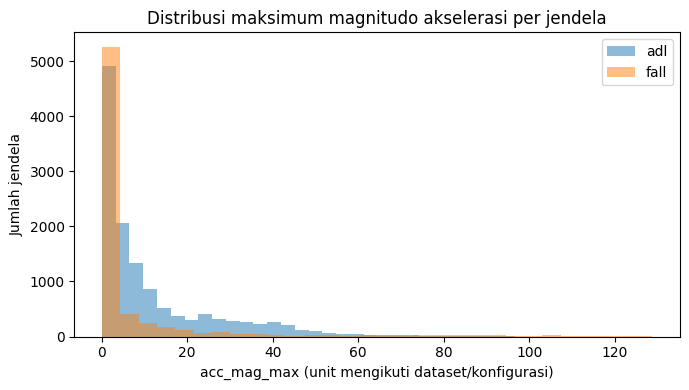

In [69]:
# Visualisasi distribusi dua fitur contoh; bukan penilaian klinis.
fig, ax = plt.subplots(figsize=(7, 4))
for label in ["adl", "fall"]:
    part = fall_features[fall_features["label"] == label]
    ax.hist(part["acc_mag_max"], bins=30, alpha=0.5, label=label)
ax.set_title("Distribusi maksimum magnitudo akselerasi per jendela")
ax.set_xlabel("acc_mag_max (unit mengikuti dataset/konfigurasi)")
ax.set_ylabel("Jumlah jendela")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Split subject-wise 70/15/15

Jendela dari satu peserta harus berada hanya pada satu subset. Ini mencegah data peserta yang sama muncul di train dan test, yang dapat membuat hasil tampak lebih baik dari kemampuan generalisasi sebenarnya.

In [70]:
def subject_wise_split(df, group_col="subject_id", random_state=RANDOM_STATE):
    groups = df[group_col].astype(str)
    if groups.nunique() < 3:
        raise ValueError(
            "Split 70/15/15 subject-wise memerlukan minimal 3 subject, dan idealnya lebih banyak. "
            "Tambah peserta/dataset atau gunakan GroupKFold dan jelaskan keterbatasan."
        )
    gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=random_state)
    train_val_idx, test_idx = next(gss_test.split(df, df["label"], groups))
    train_val = df.iloc[train_val_idx].copy()
    test = df.iloc[test_idx].copy()
    groups_tv = train_val[group_col].astype(str)
    # 15% dari total untuk validasi berarti sekitar 0.15/0.85 dari sisa.
    val_fraction_of_remaining = 0.15 / 0.85
    gss_val = GroupShuffleSplit(n_splits=1, test_size=val_fraction_of_remaining, random_state=random_state + 1)
    train_idx, val_idx = next(gss_val.split(train_val, train_val["label"], groups_tv))
    train = train_val.iloc[train_idx].copy()
    val = train_val.iloc[val_idx].copy()

    for name, subset in [("train", train), ("validation", val), ("test", test)]:
        print(f"{name}: {len(subset)} windows | {subset[group_col].nunique()} subjects | {subset['label'].value_counts().to_dict()}")
        if set(subset["label"].dropna().unique()) != {"fall", "adl"}:
            warnings.warn(f"Subset {name} belum memuat kedua kelas fall dan adl. Ubah random_state atau evaluasi dengan GroupKFold; jangan menafsirkan metrik yang tidak lengkap.")
    return train, val, test

fall_train, fall_val, fall_test = subject_wise_split(fall_features)

train_subjects = set(fall_train.subject_id)
val_subjects = set(fall_val.subject_id)
test_subjects = set(fall_test.subject_id)
assert train_subjects.isdisjoint(val_subjects)
assert train_subjects.isdisjoint(test_subjects)
assert val_subjects.isdisjoint(test_subjects)
print("Pemeriksaan subject-wise lulus: tidak ada subject yang tumpang tindih.")

train: 14475 windows | 28 subjects | {'adl': 9493, 'fall': 4982}
validation: 2149 windows | 6 subjects | {'adl': 1436, 'fall': 713}
test: 3157 windows | 7 subjects | {'adl': 1987, 'fall': 1170}
Pemeriksaan subject-wise lulus: tidak ada subject yang tumpang tindih.


## 12. Melatih Random Forest

Parameter awal mengikuti proposal: 100 pohon dan `class_weight="balanced"`. Penyesuaian hyperparameter dilakukan menggunakan validation; test hanya digunakan sekali untuk evaluasi akhir.

In [71]:
FALL_META_COLS = {"subject_id", "activity", "trial", "label", "window_start_index", "window_duration_s"}
FALL_FEATURE_COLS = [c for c in fall_features.columns if c not in FALL_META_COLS]

X_train = fall_train[FALL_FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
X_val = fall_val[FALL_FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
X_test = fall_test[FALL_FEATURE_COLS].replace([np.inf, -np.inf], np.nan)

# Isi nilai kosong menggunakan median dari train saja.
fall_medians = X_train.median()
X_train = X_train.fillna(fall_medians)
X_val = X_val.fillna(fall_medians)
X_test = X_test.fillna(fall_medians)

y_train = fall_train["label"].astype(str)
y_val = fall_val["label"].astype(str)
y_test = fall_test["label"].astype(str)

rf_model = RandomForestClassifier(
    n_estimators=RF_N_ESTIMATORS,
    class_weight=RF_CLASS_WEIGHT,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    min_samples_leaf=1,
)
rf_model.fit(X_train, y_train)
print("Random Forest selesai dilatih.")
print("Jumlah fitur:", len(FALL_FEATURE_COLS))
print("Kelas:", rf_model.classes_)

Random Forest selesai dilatih.
Jumlah fitur: 43
Kelas: ['adl' 'fall']


In [72]:
# Evaluasi validation (boleh dipakai untuk keputusan pengembangan, bukan test akhir).
val_pred = rf_model.predict(X_val)
print(classification_report(y_val, val_pred, labels=["fall", "adl"], zero_division=0))

              precision    recall  f1-score   support

        fall       0.78      0.74      0.76       713
         adl       0.87      0.90      0.88      1436

    accuracy                           0.84      2149
   macro avg       0.83      0.82      0.82      2149
weighted avg       0.84      0.84      0.84      2149



## 13. Evaluasi akhir Random Forest

Metrik utama adalah recall/sensitivitas kelas `fall`, tetapi precision, specificity, F1, confusion matrix, dan false alarm per jam juga harus dilaporkan. Target recall **≥80%** merupakan target proyek pada proposal, bukan standar medis.

,nilai
model,Random Forest
recall_fall,0.676923
precision_fall,0.760077
specificity_adl,0.874182
f1_fall,0.716094
false_alarm_per_hour_approx,285.850405
accuracy,0.801077
tp,792
fn,378
fp,250


Classification report:
              precision    recall  f1-score   support

        fall       0.76      0.68      0.72      1170
         adl       0.82      0.87      0.85      1987

    accuracy                           0.80      3157
   macro avg       0.79      0.78      0.78      3157
weighted avg       0.80      0.80      0.80      3157



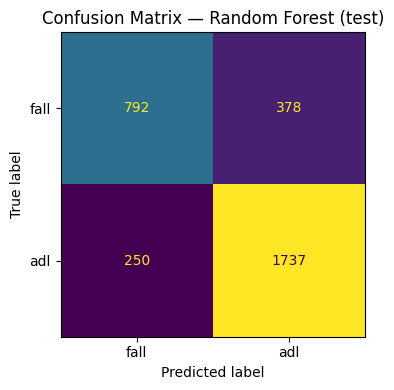

Target proyek recall ≥80% belum tercapai. Jangan menyatakan model memenuhi target; evaluasi threshold/data/fitur.


In [73]:
def fall_metrics(y_true, y_pred, subset_df, name="model"):
    labels = ["fall", "adl"]
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    # Dengan urutan [fall, adl]: TP=fall benar, FN=fall jadi ADL, FP=ADL jadi fall, TN=ADL benar.
    tp, fn, fp, tn = cm.ravel()
    recall = tp / (tp + fn) if (tp + fn) else np.nan
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else np.nan
    adl_part = subset_df[subset_df["label"] == "adl"]
    if len(adl_part):
        group_sizes = adl_part.groupby(["subject_id", "activity", "trial"]).size()
        adl_duration_seconds = sum(((n - 1) * IMU_STRIDE + IMU_WINDOW_SAMPLES) / IMU_FS_HZ for n in group_sizes)
    else:
        adl_duration_seconds = 0.0
    adl_hours = adl_duration_seconds / 3600
    false_alarm_per_hour = fp / adl_hours if adl_hours > 0 else np.nan
    result = {
        "model": name, "recall_fall": recall, "precision_fall": precision,
        "specificity_adl": specificity, "f1_fall": f1,
        "false_alarm_per_hour_approx": false_alarm_per_hour,
        "accuracy": accuracy_score(y_true, y_pred),
        "tp": int(tp), "fn": int(fn), "fp": int(fp), "tn": int(tn)
    }
    return result, cm

rf_test_pred = rf_model.predict(X_test)
rf_test_metrics, rf_cm = fall_metrics(y_test, rf_test_pred, fall_test, "Random Forest")
display(pd.DataFrame([rf_test_metrics]).T.rename(columns={0:"nilai"}))
print("Classification report:")
print(classification_report(y_test, rf_test_pred, labels=["fall", "adl"], zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(rf_cm, display_labels=["fall", "adl"]).plot(ax=ax, colorbar=False)
ax.set_title("Confusion Matrix — Random Forest (test)")
plt.tight_layout()
plt.show()

if rf_test_metrics["recall_fall"] >= 0.80:
    print("Target proyek recall ≥80% tercapai pada test split ini. Tetap laporkan metrik lain dan keterbatasan.")
else:
    print("Target proyek recall ≥80% belum tercapai. Jangan menyatakan model memenuhi target; evaluasi threshold/data/fitur.")

## 14. Baseline threshold gerakan (pembanding sederhana)

Proposal menyebut pemicu awal berupa fase percepatan rendah sekitar **<0,5 g**, benturan **>2,5 g**, dan gerakan rendah setelahnya. Nilai tersebut merupakan parameter awal eksperimen yang harus dikalibrasi. Baseline hanya dihitung jika `ACCEL_TO_G` sudah diisi dan satuan dataset sudah diverifikasi.

In [74]:
def threshold_fall_prediction(feature_df):
    if ACCEL_TO_G is None:
        raise ValueError("ACCEL_TO_G masih None. Verifikasi satuan akselerometer lalu isi konfigurasi sebelum menghitung baseline threshold.")
    # Fitur acc_mag telah dihitung setelah konversi ACCEL_TO_G.
    candidate = (
        (feature_df["acc_mag_min"] < FALL_FREEFALL_THRESHOLD_G) &
        (feature_df["acc_mag_max"] > FALL_IMPACT_THRESHOLD_G) &
        (feature_df["post_event_acc_std"] < POST_IMPACT_STD_THRESHOLD_G)
    )
    return np.where(candidate, "fall", "adl")

if ACCEL_TO_G is not None:
    baseline_pred = threshold_fall_prediction(fall_test)
    baseline_metrics, baseline_cm = fall_metrics(y_test, baseline_pred, fall_test, "Threshold baseline")
    display(pd.DataFrame([rf_test_metrics, baseline_metrics]).set_index("model"))
else:
    print("Baseline threshold dilewati karena ACCEL_TO_G belum dikonfigurasi. Random Forest tetap dievaluasi.")

Baseline threshold dilewati karena ACCEL_TO_G belum dikonfigurasi. Random Forest tetap dievaluasi.


,importance
acc_mag_min,0.076415
gyro_mag_min,0.070764
acc_mag_mean,0.047645
gz_std,0.036059
az_min,0.034568
post_event_acc_std,0.034348
ax_min,0.033925
gyro_mag_mean,0.032511
az_range,0.030716
gy_std,0.030533


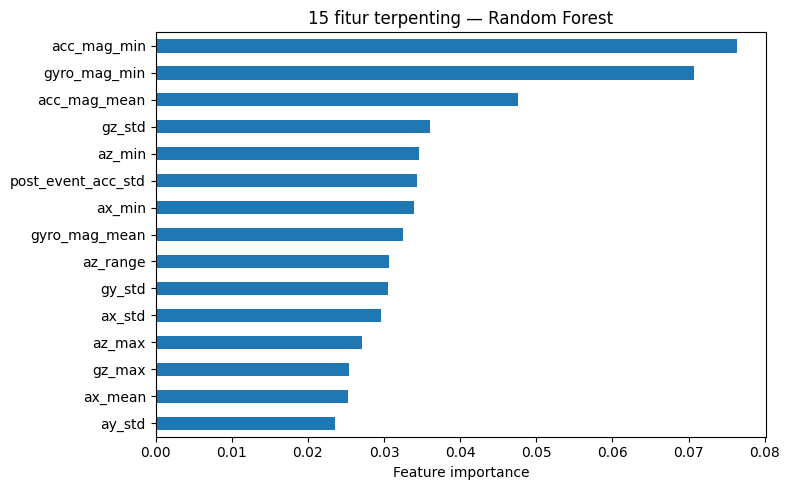

In [75]:
# Feature importance membantu melihat fitur gerak yang sering digunakan model.
importance = pd.Series(rf_model.feature_importances_, index=FALL_FEATURE_COLS).sort_values(ascending=False)
display(importance.head(15).to_frame("importance"))
fig, ax = plt.subplots(figsize=(8, 5))
importance.head(15).sort_values().plot(kind="barh", ax=ax)
ax.set_title("15 fitur terpenting — Random Forest")
ax.set_xlabel("Feature importance")
plt.tight_layout()
plt.show()

## 15. Simpan model Random Forest

Model disimpan bersama daftar fitur dan median imputasi. Backend harus memakai daftar fitur dan fungsi ekstraksi yang sama persis dengan notebook ini.

In [76]:
fall_artifact = {
    "model": rf_model,
    "feature_columns": FALL_FEATURE_COLS,
    "medians": fall_medians.to_dict(),
    "imu_fs_hz": IMU_FS_HZ,
    "window_seconds": IMU_WINDOW_SECONDS,
    "window_samples": IMU_WINDOW_SAMPLES,
    "overlap": IMU_OVERLAP,
    "accel_to_g": ACCEL_TO_G,
    "gyro_to_dps": GYRO_TO_DPS,
    "class_names": list(rf_model.classes_),
    "random_state": RANDOM_STATE,
    "test_metrics": rf_test_metrics,
    "note": "Prototype fall/ADL classifier; not a medical or guaranteed fall detector."
}
fall_model_path = ARTIFACT_DIR / "biopulse_random_forest_fall.joblib"
joblib.dump(fall_artifact, fall_model_path)
print("Model tersimpan:", fall_model_path)

Model tersimpan: artifacts_biopulse/biopulse_random_forest_fall.joblib


## 16. Contoh inferensi satu jendela IMU baru

Fungsi ini dipanggil backend setelah ESP32 mengirim kandidat jatuh dan backend menerima jendela sekitar 3 detik. Contoh ini memakai satu potongan dari dataset sebagai demonstrasi kode, **bukan pengujian pada perangkat nyata**.

In [77]:
def predict_fall_window(new_window_df, artifact=fall_artifact):
    if len(new_window_df) != artifact["window_samples"]:
        raise ValueError(f"Jendela harus {artifact['window_samples']} sampel, diterima {len(new_window_df)}")
    feat = extract_fall_window_features(
        new_window_df,
        accel_to_g=artifact["accel_to_g"],
        gyro_to_dps=artifact["gyro_to_dps"]
    )
    X = pd.DataFrame([feat]).reindex(columns=artifact["feature_columns"])
    X = X.fillna(pd.Series(artifact["medians"]))
    model = artifact["model"]
    pred = model.predict(X)[0]
    proba = model.predict_proba(X)[0]
    return {"prediction": str(pred), "probabilities": dict(zip(model.classes_, proba))}

first_group_key, sample_group = next(iter(fall_raw.groupby(["subject_id", "activity", "trial"], sort=False)))
if len(sample_group) >= IMU_WINDOW_SAMPLES:
    sample_result = predict_fall_window(sample_group.iloc[:IMU_WINDOW_SAMPLES])
    print(sample_result)
else:
    print("Tidak ada trial yang cukup panjang untuk contoh inferensi 60 sampel.")

{'prediction': 'adl', 'probabilities': {'adl': np.float64(0.96), 'fall': np.float64(0.04)}}


# PIPELINE B — DETEKSI ANOMALI BPM DAN SpO₂ DENGAN ISOLATION FOREST

## 17. Muat dan validasi data tanda vital

Data ini harus berasal dari pembacaan MAX30102 yang dikumpulkan dalam kondisi normal dan aman. `signal_ok=False` dikeluarkan dari statistik BPM/SpO₂. Jika kualitas sinyal tidak baik, kondisi itu harus ditandai sebagai kualitas data rendah, bukan anomali fisiologis.

In [78]:
def to_bool_signal(series):
    mapping = {
        "true": True, "1": True, "yes": True, "y": True, "valid": True,
        "false": False, "0": False, "no": False, "n": False, "invalid": False
    }
    return series.astype(str).str.strip().str.lower().map(mapping)


def load_vitals_csv(path):
    if not Path(path).exists() or Path(path).stat().st_size <= 5:
        raise FileNotFoundError(f"File vital belum diisi: {path}. Rekam data normal MAX30102 terlebih dahulu.")
    df = pd.read_csv(path)
    aliases = {
        "timestamp": ["timestamp", "datetime", "ts", "timestamp_iso"],
        "subject_id": ["subject_id", "device_id", "user_id"],
        "bpm": ["bpm", "heart_rate", "heart_rate_bpm"],
        "spo2_est": ["spo2_est", "spo2", "spo2_pct", "spo2_percent"],
        "signal_ok": ["signal_ok", "ppg_valid", "valid_signal"],
        "activity_level": ["activity_level", "acc_mag_mean", "acc_mag_g", "activity_index"]
    }
    lower_map = {str(c).strip().lower(): c for c in df.columns}
    rename = {}
    for canonical, options in aliases.items():
        found = next((lower_map[o] for o in options if o in lower_map), None)
        if found is not None and found != canonical:
            rename[found] = canonical
    df = df.rename(columns=rename)
    required = {"timestamp", "bpm", "spo2_est", "signal_ok"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Kolom vital wajib belum ada: {sorted(missing)}")
    if "subject_id" not in df.columns:
        df["subject_id"] = "BP-01"
    if "activity_level" in df.columns:
        df["activity_level"] = pd.to_numeric(df["activity_level"], errors="coerce")
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    df["bpm"] = pd.to_numeric(df["bpm"], errors="coerce")
    df["spo2_est"] = pd.to_numeric(df["spo2_est"], errors="coerce")
    df["signal_ok"] = to_bool_signal(df["signal_ok"])
    df = df.dropna(subset=["timestamp", "signal_ok"]).copy()
    df["subject_id"] = df["subject_id"].astype(str)
    df = df.sort_values(["subject_id", "timestamp"]).reset_index(drop=True)
    return df

if not CONFIRM_VITALS_DATA_IS_NORMAL_BASELINE:
    raise RuntimeError(
        "Konfirmasi dulu isi data: pastikan VITALS_CSV hanya berisi baseline kondisi normal yang valid, "
        "lalu ubah CONFIRM_VITALS_DATA_IS_NORMAL_BASELINE=True pada bagian konfigurasi."
    )

vitals_raw = load_vitals_csv(VITALS_CSV)
print("Bentuk vital:", vitals_raw.shape)
print("Subjek/perangkat:", vitals_raw["subject_id"].nunique())
print("Proporsi signal_ok:", vitals_raw["signal_ok"].mean())
display(vitals_raw.head())

Bentuk vital: (720, 6)
Subjek/perangkat: 1
Proporsi signal_ok: 1.0


,subject_id,timestamp,bpm,spo2_est,signal_ok,activity_level
0,BP-01,2023-10-01 08:00:00,73.490142,98.653901,True,0.166467
1,BP-01,2023-10-01 08:00:30,71.725021,97.644916,True,0.148424
2,BP-01,2023-10-01 08:01:00,74.222650,97.825907,True,0.076614
3,BP-01,2023-10-01 08:01:30,76.988359,98.871632,True,0.131754
4,BP-01,2023-10-01 08:02:00,71.856367,98.585433,True,0.197700


## 18. Pemeriksaan kualitas dan interval telemetri

Rancangan telemetri normal adalah 30 detik. Cell ini memeriksa interval aktual dan menghitung berapa sampel valid yang tersedia. Jangan gunakan data invalid untuk membangun baseline normal.

In [79]:
intervals = []
for sid, g in vitals_raw.groupby("subject_id"):
    delta = g["timestamp"].diff().dt.total_seconds().dropna()
    if len(delta):
        intervals.extend(delta.tolist())
if intervals:
    print("Interval telemetry median (detik):", float(np.median(intervals)))
    print("Interval telemetry min/max (detik):", float(np.min(intervals)), float(np.max(intervals)))

valid_mask = (
    vitals_raw["signal_ok"].fillna(False) &
    vitals_raw["bpm"].notna() &
    vitals_raw["spo2_est"].notna() &
    np.isfinite(vitals_raw["bpm"]) &
    np.isfinite(vitals_raw["spo2_est"]) &
    (vitals_raw["bpm"] > 0) &
    vitals_raw["spo2_est"].between(0, 100)
)
print("Jumlah baris:", len(vitals_raw))
print("Jumlah baris valid:", int(valid_mask.sum()))
print("Jumlah baris tidak valid/tidak lengkap:", int((~valid_mask).sum()))

Interval telemetry median (detik): 30.0
Interval telemetry min/max (detik): 30.0 30.0
Jumlah baris: 720
Jumlah baris valid: 720
Jumlah baris tidak valid/tidak lengkap: 0


## 19. Membuat fitur tren pada jendela berjalan 5 menit

Fitur awal sesuai proposal:
- BPM: mean, minimum, maksimum, standar deviasi, dan slope/tren.
- SpO₂: mean, minimum, maksimum, standar deviasi, dan slope/tren.
- Proporsi pembacaan yang valid.
- Rata-rata aktivitas dari MPU6050 jika kolom `activity_level` tersedia.

Fitur dihitung hanya jika jendela memiliki minimal `VITAL_MIN_VALID_SAMPLES` sampel valid dan proporsi valid memenuhi konfigurasi. Jendela diperbarui setiap kali telemetri baru diterima.

In [80]:
def linear_slope_per_minute(times, values):
    if len(values) < 2:
        return 0.0
    x = (times - times.iloc[0]).dt.total_seconds().to_numpy() / 60.0
    if np.allclose(x, x[0]):
        return 0.0
    return float(np.polyfit(x, np.asarray(values, dtype=float), 1)[0])


def build_vital_window_features(df):
    rows = []
    use_activity = "activity_level" in df.columns and df["activity_level"].notna().any()
    window_delta = pd.Timedelta(minutes=VITAL_WINDOW_MINUTES)

    for sid, group in df.groupby("subject_id"):
        g = group.sort_values("timestamp").reset_index(drop=True)
        for i, end_row in g.iterrows():
            end_time = end_row["timestamp"]
            start_time = end_time - window_delta
            # Tunggu sampai perangkat memiliki riwayat penuh 5 menit pada subset tersebut.
            if end_time - g.iloc[0]["timestamp"] < window_delta:
                continue
            w_all = g[(g["timestamp"] >= start_time) & (g["timestamp"] <= end_time)]
            if len(w_all) == 0:
                continue
            good_mask = (
                w_all["signal_ok"].fillna(False) &
                w_all["bpm"].notna() & w_all["spo2_est"].notna() &
                np.isfinite(w_all["bpm"]) & np.isfinite(w_all["spo2_est"]) &
                (w_all["bpm"] > 0) & w_all["spo2_est"].between(0, 100)
            )
            w = w_all[good_mask].copy()
            valid_ratio = len(w) / len(w_all)
            if len(w) < VITAL_MIN_VALID_SAMPLES or valid_ratio < VITAL_MIN_VALID_RATIO:
                continue

            feat = {
                "bpm_mean": float(w["bpm"].mean()),
                "bpm_min": float(w["bpm"].min()),
                "bpm_max": float(w["bpm"].max()),
                "bpm_std": float(w["bpm"].std(ddof=0)),
                "bpm_slope_per_min": linear_slope_per_minute(w["timestamp"], w["bpm"]),
                "spo2_mean": float(w["spo2_est"].mean()),
                "spo2_min": float(w["spo2_est"].min()),
                "spo2_max": float(w["spo2_est"].max()),
                "spo2_std": float(w["spo2_est"].std(ddof=0)),
                "spo2_slope_per_min": linear_slope_per_minute(w["timestamp"], w["spo2_est"]),
                "valid_ratio": float(valid_ratio),
                "valid_sample_count": int(len(w)),
                "subject_id": str(sid),
                "window_start": start_time,
                "window_end": end_time,
            }
            if use_activity:
                activity_values = pd.to_numeric(w.get("activity_level"), errors="coerce").dropna()
                feat["activity_mean"] = float(activity_values.mean()) if len(activity_values) else np.nan
            rows.append(feat)
    return pd.DataFrame(rows)

vital_windows_all = build_vital_window_features(vitals_raw)
print("Jumlah window vital yang memenuhi quality gate:", len(vital_windows_all))
if vital_windows_all.empty:
    raise ValueError(
        "Belum ada window vital 5 menit yang memenuhi quality gate. Rekam baseline lebih lama; "
        "pada interval 30 detik diperlukan beberapa pembacaan valid dalam satu jendela."
    )
display(vital_windows_all.head())

Jumlah window vital yang memenuhi quality gate: 710


,bpm_mean,bpm_min,bpm_max,bpm_std,bpm_slope_per_min,spo2_mean,spo2_min,spo2_max,spo2_std,spo2_slope_per_min,valid_ratio,valid_sample_count,subject_id,window_start,window_end,activity_mean
0,73.792746,71.706500,77.575025,2.067128,-0.001315,98.373790,97.644916,98.871632,0.363326,0.042265,1.0,11,BP-01,2023-10-01 08:00:00,2023-10-01 08:05:00,0.131281
1,73.669222,71.706500,77.575025,2.121404,-0.185360,98.315328,97.644916,98.871632,0.365284,0.039825,1.0,11,BP-01,2023-10-01 08:00:30,2023-10-01 08:05:30,0.123605
2,73.911625,71.706500,77.575025,2.036023,-0.331796,98.411620,97.825907,98.871632,0.311517,0.002034,1.0,11,BP-01,2023-10-01 08:01:00,2023-10-01 08:06:00,0.121555
3,73.351587,68.062227,77.575025,2.633144,-0.829630,98.395511,97.648708,98.871632,0.344251,-0.131217,1.0,11,BP-01,2023-10-01 08:01:30,2023-10-01 08:06:30,0.130600
4,72.603850,68.062227,77.575025,2.661926,-0.850012,98.408506,97.648708,99.014578,0.364104,-0.022998,1.0,11,BP-01,2023-10-01 08:02:00,2023-10-01 08:07:00,0.133160


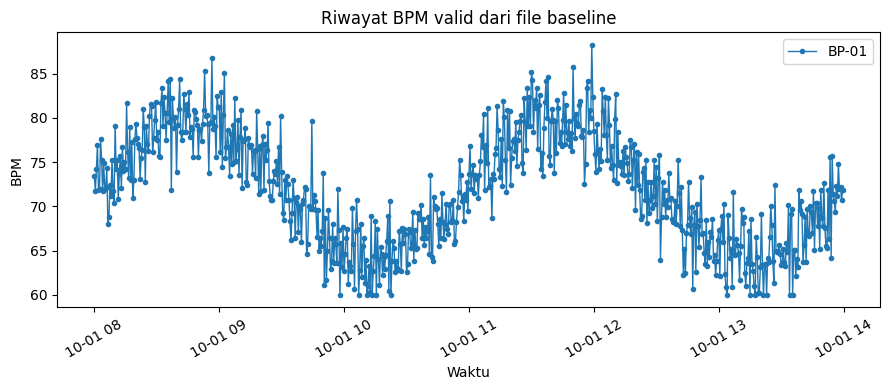

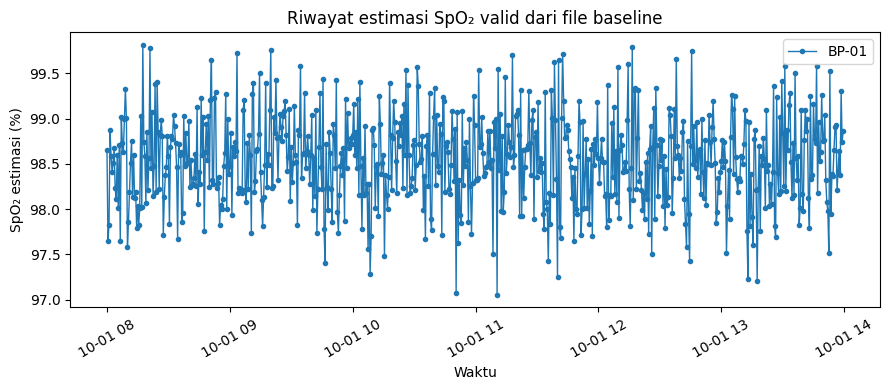

In [81]:
fig, ax = plt.subplots(figsize=(9, 4))
for sid, g in vitals_raw.groupby("subject_id"):
    good = g[g["signal_ok"].fillna(False)]
    ax.plot(good["timestamp"], good["bpm"], marker=".", linewidth=1, label=str(sid))
ax.set_title("Riwayat BPM valid dari file baseline")
ax.set_xlabel("Waktu")
ax.set_ylabel("BPM")
if vitals_raw["subject_id"].nunique() <= 8:
    ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for sid, g in vitals_raw.groupby("subject_id"):
    good = g[g["signal_ok"].fillna(False)]
    ax.plot(good["timestamp"], good["spo2_est"], marker=".", linewidth=1, label=str(sid))
ax.set_title("Riwayat estimasi SpO₂ valid dari file baseline")
ax.set_xlabel("Waktu")
ax.set_ylabel("SpO₂ estimasi (%)")
if vitals_raw["subject_id"].nunique() <= 8:
    ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 20. Pembagian data vital secara kronologis

Karena jendela 5 menit saling tumpang tindih, pembagian dilakukan pada data mentah terlebih dahulu per subjek: 70% waktu awal untuk train, 15% berikutnya untuk validation, dan 15% terakhir untuk test. Fitur jendela dibuat secara terpisah di setiap subset, sehingga jendela tidak melintasi batas subset. Setiap subset memerlukan pemanasan jendela 5 menit sendiri; bila data terlalu singkat, tambah durasi rekaman.

Pada tahap awal, data dianggap baseline normal karena file yang digunakan memang disiapkan untuk kondisi normal. Isolation Forest bukan model yang memerlukan contoh label anomali saat pelatihan.

In [82]:
def chronological_split_raw_vitals(df):
    train_parts, val_parts, test_parts = [], [], []
    for sid, g in df.sort_values("timestamp").groupby("subject_id"):
        g = g.sort_values("timestamp").reset_index(drop=True)
        n = len(g)
        i1 = int(n * 0.70)
        i2 = int(n * 0.85)
        if i1 <= 0 or i2 <= i1 or n - i2 <= 0:
            continue
        train_parts.append(g.iloc[:i1].copy())
        val_parts.append(g.iloc[i1:i2].copy())
        test_parts.append(g.iloc[i2:].copy())
    if not train_parts or not val_parts or not test_parts:
        raise ValueError("Data vital terlalu sedikit untuk split kronologis 70/15/15. Tambah durasi rekaman per subjek.")
    return pd.concat(train_parts), pd.concat(val_parts), pd.concat(test_parts)

vital_raw_train, vital_raw_val, vital_raw_test = chronological_split_raw_vitals(vitals_raw)

vital_train = build_vital_window_features(vital_raw_train)
vital_val = build_vital_window_features(vital_raw_val)
vital_test = build_vital_window_features(vital_raw_test)

print("Window train/validation/test:", len(vital_train), len(vital_val), len(vital_test))
if min(len(vital_train), len(vital_val), len(vital_test)) < 5:
    raise ValueError(
        "Window pada salah satu subset <5. Rekam baseline normal lebih lama agar setiap subset memiliki cukup jendela 5 menit."
    )
display(pd.DataFrame({
    "subset": ["train", "validation", "test"],
    "n_windows": [len(vital_train), len(vital_val), len(vital_test)],
    "subjects": [vital_train.subject_id.nunique(), vital_val.subject_id.nunique(), vital_test.subject_id.nunique()]
}))

Window train/validation/test: 493 99 98


,subset,n_windows,subjects
0,train,493,1
1,validation,99,1
2,test,98,1


## 21. Melatih Isolation Forest dan mengkalibrasi skor

Isolation Forest dilatih hanya menggunakan fitur jendela normal valid dari train. Skor `score_samples` yang lebih kecil menunjukkan observasi yang lebih mudah diisolasi. Ambang ditentukan dari kuantil bawah skor validation normal, bukan dari label penyakit.

Pengaturan kuantil 5% adalah parameter eksperimen untuk mengendalikan tingkat penandaan pada baseline normal. Angka tersebut bukan ambang medis dan perlu dilaporkan sebagai pilihan metodologis.

In [83]:
VITAL_META_COLS = {"subject_id", "window_start", "window_end", "valid_sample_count"}
VITAL_FEATURE_COLS = [c for c in vital_train.columns if c not in VITAL_META_COLS]

X_vital_train = vital_train[VITAL_FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
X_vital_val = vital_val[VITAL_FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
X_vital_test = vital_test[VITAL_FEATURE_COLS].replace([np.inf, -np.inf], np.nan)

# Isi nilai kosong menggunakan median data train saja. activity_mean mungkin kosong bila data MPU6050 tidak tersedia.
vital_medians = X_vital_train.median(numeric_only=True)
X_vital_train = X_vital_train.fillna(vital_medians).fillna(0)
X_vital_val = X_vital_val.fillna(vital_medians).fillna(0)
X_vital_test = X_vital_test.fillna(vital_medians).fillna(0)

if "activity_mean" not in VITAL_FEATURE_COLS:
    warnings.warn("Kolom activity_level dari MPU6050 tidak tersedia. Model berjalan tanpa konteks aktivitas; tambahkan kolom ini untuk eksperimen final.")

if len(X_vital_train) < 10:
    raise ValueError("Jumlah window train terlalu sedikit untuk melatih Isolation Forest secara bermakna.")

if_model = IsolationForest(
    n_estimators=IF_N_ESTIMATORS,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
if_model.fit(X_vital_train)

val_scores = if_model.score_samples(X_vital_val)
if_threshold = float(np.quantile(val_scores, IF_VALIDATION_LOWER_QUANTILE))
print("Isolation Forest selesai dilatih.")
print("Jumlah fitur:", len(VITAL_FEATURE_COLS))
print("Ambang skor hasil validation:", if_threshold)

Isolation Forest selesai dilatih.
Jumlah fitur: 12
Ambang skor hasil validation: -0.5516336088852982


## 22. Evaluasi Isolation Forest pada baseline normal

Karena tidak tersedia ground truth klinis untuk anomali BPM/SpO₂, metrik yang tepat di sini bukan akurasi/recall penyakit. Laporkan proporsi jendela normal yang ditandai, frekuensi alert setelah aturan dua pembaruan berturut-turut, kestabilan skor antarwaktu, serta hasil uji sintetis secara terpisah.

In [84]:
def score_vital_windows(feature_df, model, threshold, require_two_consecutive=True):
    X = feature_df[VITAL_FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
    X = X.fillna(vital_medians).fillna(0)
    out = feature_df.copy()
    out["anomaly_score"] = model.score_samples(X)
    out["anomaly_candidate"] = out["anomaly_score"] <= threshold
    out = out.sort_values(["subject_id", "window_end"]).reset_index(drop=True)
    if require_two_consecutive:
        out["anomaly_alert"] = out.groupby("subject_id")["anomaly_candidate"].transform(
            lambda s: s.fillna(False) & s.shift(1, fill_value=False)
        )
    else:
        out["anomaly_alert"] = out["anomaly_candidate"]
    return out

val_scored = score_vital_windows(vital_val, if_model, if_threshold, REQUIRE_TWO_CONSECUTIVE_IF_FLAGS)
test_scored = score_vital_windows(vital_test, if_model, if_threshold, REQUIRE_TWO_CONSECUTIVE_IF_FLAGS)

summary_if = pd.DataFrame([
    {"subset": "validation", "candidate_rate": val_scored["anomaly_candidate"].mean(), "alert_rate_after_persistence": val_scored["anomaly_alert"].mean()},
    {"subset": "test", "candidate_rate": test_scored["anomaly_candidate"].mean(), "alert_rate_after_persistence": test_scored["anomaly_alert"].mean()},
])
display(summary_if)
print("Catatan: karena validation/test merupakan baseline normal, angka di atas adalah proporsi false flag pada data baseline, bukan sensitivitas deteksi penyakit.")

,subset,candidate_rate,alert_rate_after_persistence
0,validation,0.050505,0.020202
1,test,0.040816,0.020408


Catatan: karena validation/test merupakan baseline normal, angka di atas adalah proporsi false flag pada data baseline, bukan sensitivitas deteksi penyakit.


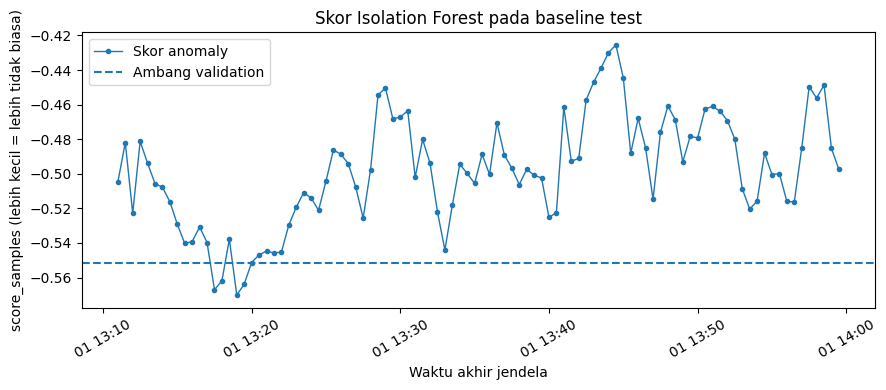

In [85]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(test_scored["window_end"], test_scored["anomaly_score"], marker=".", linewidth=1, label="Skor anomaly")
ax.axhline(if_threshold, linestyle="--", label="Ambang validation")
ax.set_title("Skor Isolation Forest pada baseline test")
ax.set_xlabel("Waktu akhir jendela")
ax.set_ylabel("score_samples (lebih kecil = lebih tidak biasa)")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 23. Baseline aturan BPM/SpO₂ (opsional, harus dikonfigurasi)

Proposal menyatakan aturan rentang tetap dipakai sebagai baseline yang mudah dijelaskan. Namun, proposal tidak menetapkan angka ambang fisiologis final. Karena itu notebook **tidak mengarang ambang klinis**. Isi `BPM_LOW_LIMIT`, `BPM_HIGH_LIMIT`, dan/atau `SPO2_LOW_LIMIT` hanya setelah kelompok memilih rujukan tepercaya dan mendapatkan arahan pembimbing/tenaga kesehatan.

Jika aturan dasar memicu peringatan, backend sebaiknya tidak menunggu Isolation Forest untuk membuat event. Hasil aturan dan hasil model dicatat sebagai sumber keputusan yang berbeda.

In [86]:
def apply_vital_rule_baseline(feature_df):
    out = feature_df.copy()
    rule_flags = pd.Series(False, index=out.index)
    rule_reasons = []
    for idx, row in out.iterrows():
        reasons = []
        if BPM_LOW_LIMIT is not None and row["bpm_min"] < BPM_LOW_LIMIT:
            reasons.append("bpm_below_configured_limit")
        if BPM_HIGH_LIMIT is not None and row["bpm_max"] > BPM_HIGH_LIMIT:
            reasons.append("bpm_above_configured_limit")
        if SPO2_LOW_LIMIT is not None and row["spo2_min"] < SPO2_LOW_LIMIT:
            reasons.append("spo2_below_configured_limit")
        rule_flags.loc[idx] = len(reasons) > 0
        rule_reasons.append(";".join(reasons))
    out["rule_alert"] = rule_flags
    out["rule_reason"] = rule_reasons
    return out

test_scored = apply_vital_rule_baseline(test_scored)
if BPM_LOW_LIMIT is None and BPM_HIGH_LIMIT is None and SPO2_LOW_LIMIT is None:
    print("Aturan fisiologis belum diaktifkan: semua threshold masih None. Ini disengaja agar tidak memakai angka tanpa dasar.")
else:
    print("Jumlah window yang memicu aturan:", int(test_scored["rule_alert"].sum()))

Aturan fisiologis belum diaktifkan: semua threshold masih None. Ini disengaja agar tidak memakai angka tanpa dasar.


## 24. Uji sintetis alur perangkat lunak (terpisah dari evaluasi)

Cell ini membuat salinan fitur test dengan gangguan angka buatan secara terkontrol untuk memastikan model dapat memberi skor pada pola yang sengaja digeser. **Ini bukan data pasien, bukan label medis, dan tidak boleh dilaporkan sebagai kemampuan deteksi klinis.** Data sintetis tidak digunakan saat pelatihan atau dalam metrik utama.

In [87]:
synthetic_stress = X_vital_test.copy().head(min(20, len(X_vital_test))).copy()
if len(synthetic_stress):
    if "bpm_mean" in synthetic_stress.columns:
        synthetic_stress["bpm_mean"] = synthetic_stress["bpm_mean"] + 25
    if "spo2_min" in synthetic_stress.columns:
        synthetic_stress["spo2_min"] = np.maximum(0, synthetic_stress["spo2_min"] - 5)
    synthetic_scores = if_model.score_samples(synthetic_stress)
    synthetic_result = pd.DataFrame({
        "synthetic_score": synthetic_scores,
        "flagged_by_calibrated_threshold": synthetic_scores <= if_threshold
    })
    display(synthetic_result.head(20))
    print("Proporsi sampel sintetis yang berada di bawah ambang:", float((synthetic_scores <= if_threshold).mean()))
    print("Interpretasi terbatas pada uji jalur kode; bukan recall/accuracy kondisi medis.")

,synthetic_score,flagged_by_calibrated_threshold
0,-0.546713,False
1,-0.519394,False
2,-0.540676,False
3,-0.536124,False
4,-0.521278,False
5,-0.535811,False
6,-0.536746,False
7,-0.555477,True
8,-0.555924,True
9,-0.567920,True


Proporsi sampel sintetis yang berada di bawah ambang: 0.6
Interpretasi terbatas pada uji jalur kode; bukan recall/accuracy kondisi medis.


## 25. Simpan model Isolation Forest dan metadata

In [88]:
vital_artifact = {
    "model": if_model,
    "feature_columns": VITAL_FEATURE_COLS,
    "medians": vital_medians.to_dict(),
    "score_threshold": if_threshold,
    "validation_lower_quantile": IF_VALIDATION_LOWER_QUANTILE,
    "window_minutes": VITAL_WINDOW_MINUTES,
    "min_valid_samples": VITAL_MIN_VALID_SAMPLES,
    "min_valid_ratio": VITAL_MIN_VALID_RATIO,
    "require_two_consecutive_flags": REQUIRE_TWO_CONSECUTIVE_IF_FLAGS,
    "n_estimators": IF_N_ESTIMATORS,
    "note": "Exploratory anomaly flagger trained on valid normal baseline; not a clinical detector."
}
vital_model_path = ARTIFACT_DIR / "biopulse_isolation_forest_vitals.joblib"
joblib.dump(vital_artifact, vital_model_path)
print("Model tersimpan:", vital_model_path)

Model tersimpan: artifacts_biopulse/biopulse_isolation_forest_vitals.joblib


## 26. Contoh inferensi vital untuk backend

Backend menerima telemetri tiap 30 detik, memeriksa `signal_ok`, memperbarui buffer 5 menit, lalu menghitung fitur. Rule baseline (bila sudah dikonfigurasi) dapat memicu event segera. Isolation Forest merupakan pemeriksaan tambahan; alert berbasis model pada rancangan awal baru diteruskan bila dua pembaruan valid berturut-turut ditandai.

In [89]:
def predict_vital_feature_row(feature_row, artifact=vital_artifact, previous_candidate=False):
    model = artifact["model"]
    cols = artifact["feature_columns"]
    medians = pd.Series(artifact["medians"])
    X = pd.DataFrame([feature_row]).reindex(columns=cols).replace([np.inf, -np.inf], np.nan)
    X = X.fillna(medians).fillna(0)
    score = float(model.score_samples(X)[0])
    candidate = score <= artifact["score_threshold"]
    alert = bool(candidate and previous_candidate) if artifact["require_two_consecutive_flags"] else bool(candidate)
    return {
        "anomaly_score": score,
        "anomaly_candidate": bool(candidate),
        "anomaly_alert_after_persistence": alert,
    }

example_row = vital_test.iloc[-1][VITAL_FEATURE_COLS].to_dict()
print(predict_vital_feature_row(example_row, previous_candidate=False))

{'anomaly_score': -0.4974551415124417, 'anomaly_candidate': False, 'anomaly_alert_after_persistence': False}


# 27. Integrasi dua pipeline (konsep backend)

Dua model tidak digabung menjadi satu classifier karena input dan targetnya berbeda. Backend mengelola keduanya secara paralel:

- **Pipeline A — IMU:** threshold lokal membentuk kandidat → ESP32 mengirim jendela 3 detik → backend memvalidasi → ekstraksi fitur → Random Forest → kelas `fall`/`adl` → event dan notifikasi jika aturan event terpenuhi.
- **Pipeline B — tanda vital:** telemetri BPM/SpO₂ diterima → quality gate PPG → jika valid, perbarui jendela 5 menit → baseline aturan (jika dikonfigurasi) dan Isolation Forest → catat skor/flag → alert model setelah dua pembaruan valid berturut-turut bila aturan proyek tersebut dipakai.
- **SOS dan alarm lokal:** tidak menunggu kedua model. ESP32 memberi respons lokal segera dan mengirim event dengan prioritas tertinggi jika koneksi tersedia.
- **Offline:** jika MQTT terputus, event penting disimpan di antrean lokal (LittleFS). MQTT LWT memberi status offline kepada backend yang masih terhubung ke internet; backend mengirim Telegram dan memperbarui dashboard. Waktu notifikasi tidak dapat dijamin nol detik.

Notebook ini melatih dan menguji model. Kode komunikasi MQTT, penyimpanan SQLite, API FastAPI, dan Telegram Bot API merupakan modul backend terpisah yang mengonsumsi hasil model ini.

In [90]:
# Simpan metadata keseluruhan proyek agar konfigurasi dan hasil dapat ditelusuri.
project_metadata = {
    "project": "BioPulse Care",
    "random_state": RANDOM_STATE,
    "imu_fs_hz": IMU_FS_HZ,
    "imu_window_seconds": IMU_WINDOW_SECONDS,
    "imu_window_samples": IMU_WINDOW_SAMPLES,
    "imu_overlap": IMU_OVERLAP,
    "telemetry_interval_seconds": 30,
    "heartbeat_interval_seconds": 5,
    "vital_window_minutes": VITAL_WINDOW_MINUTES,
    "rf_n_estimators": RF_N_ESTIMATORS,
    "if_n_estimators": IF_N_ESTIMATORS,
    "fall_test_metrics": rf_test_metrics,
    "vital_validation_false_flag_rate": float(val_scored["anomaly_candidate"].mean()),
    "vital_test_false_flag_rate": float(test_scored["anomaly_candidate"].mean()),
    "warning": "Prototype research only; not medical diagnosis or safety guarantee."
}
metadata_path = ARTIFACT_DIR / "biopulse_ml_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(project_metadata, f, indent=2, ensure_ascii=False, default=float)

fall_features.to_csv(ARTIFACT_DIR / "fall_window_features.csv", index=False)
vital_windows_all.to_csv(ARTIFACT_DIR / "vital_5min_features.csv", index=False)
test_scored.to_csv(ARTIFACT_DIR / "vital_test_scored.csv", index=False)
print("Metadata dan fitur tersimpan di:", ARTIFACT_DIR.resolve())

Metadata dan fitur tersimpan di: /content/artifacts_biopulse


In [91]:
import zipfile
from pathlib import Path
from google.colab import files

# Menentukan lokasi folder dan berkas zip output
artifacts_path = Path("/content/artifacts_biopulse")
zip_output_path = Path("/content/artifacts_biopulse_all.zip")

if artifacts_path.exists():
    print(f"Mengompresi seluruh berkas di {artifacts_path}...")
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for file in artifacts_path.rglob('*'):
            if file.is_file():
                zipf.write(file, file.relative_to(artifacts_path.parent))
    print(f"Kompresi selesai! Berkas disimpan di: {zip_output_path}")

    # Memulai proses unduh otomatis di browser Colab
    print("Memulai pengunduhan berkas...")
    files.download(str(zip_output_path))
else:
    print(f"Folder {artifacts_path} tidak ditemukan. Harap pastikan pipeline pelatihan sudah selesai dijalankan.")

Mengompresi seluruh berkas di /content/artifacts_biopulse...
Kompresi selesai! Berkas disimpan di: /content/artifacts_biopulse_all.zip
Memulai pengunduhan berkas...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 28. Checklist sebelum model dipakai pada backend/perangkat

- [ ] Dataset BITS-2 sudah disertai pemetaan `subject_id`, `activity`, `trial`, dan label `fall`/`adl` yang benar.
- [ ] Unit dan skala akselerometer/giroskop dataset sudah diperiksa terhadap MPU6050; lakukan kalibrasi/normalisasi yang sama saat inferensi.
- [ ] Split jatuh benar-benar subject-wise; tidak ada peserta yang muncul di train, validation, dan test sekaligus.
- [ ] Random Forest dievaluasi memakai recall, precision, specificity, F1, confusion matrix, dan false alarm per jam.
- [ ] Data vital baseline benar-benar berasal dari sesi normal dan `signal_ok=True`; data invalid tidak masuk model.
- [ ] Konteks aktivitas dari MPU6050 ditambahkan jika tersedia.
- [ ] Pembagian vital berdasarkan waktu, tanpa mengacak jendela overlap.
- [ ] Ambang aturan BPM/SpO₂ ditetapkan hanya setelah ditinjau dari sumber yang dapat dipertanggungjawabkan; notebook tidak mengisi angka secara otomatis.
- [ ] Uji sintetis dipisahkan dari hasil pengujian data nyata.
- [ ] Inferensi backend mencatat `model_version`, waktu, `message_id`, skor/kelas, dan alasan event agar dapat diaudit.
- [ ] SOS dan alarm lokal tidak menunggu hasil ML.

## 29. Sumber data dan referensi

1. Nandi, P. dkk. (2024). *Inertial measurement and heart-rate sensor-based dataset for geriatric fall detection using custom built wrist-worn device*. Data in Brief, 52, 109812. [DOI](https://doi.org/10.1016/j.dib.2023.109812). [BITS-2 Zenodo](https://zenodo.org/records/10013090).
2. Reiss, A., Indlekofer, I., Schmidt, P. (2019). *PPG-DaLiA*. UCI Machine Learning Repository. [Dataset](https://archive.ics.uci.edu/dataset/495/ppg%20dalia). Dataset ini berguna sebagai referensi PPG dan heart-rate dengan ECG sebagai acuan, bukan sebagai label SpO₂ yang langsung setara dengan MAX30102.
3. Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5–32. [DOI](https://doi.org/10.1023/A:1010933404324).
4. Liu, F. T., Ting, K. M., Zhou, Z.-H. (2008). Isolation Forest. *IEEE International Conference on Data Mining*. [DOI](https://doi.org/10.1109/ICDM.2008.17).

---

**Akhir notebook.** Jika model telah berhasil dilatih, berkas `.joblib`, metadata, dan file fitur berada di folder `artifacts_biopulse/`. Hasilnya harus diuji lagi dengan data perangkat BioPulse Care sebelum digunakan pada sistem operasional.